# Five-year stock and sector dependence

How much distinct daily-return behaviour does this dataset contain, and are stocks
within sectors more dependent than stocks across sectors? This notebook reconstructs
supported security histories, audits five-year coverage, and compares dependence on
both available paired dates and a common complete-date sample.

**Financial input:** `Data/BMG9156K1018_10.09.2026_14.59.34.csv` only.
**Window:** 8 September 2021–8 September 2026, inclusive. **Eligibility:** valid
adjusted prices at both boundaries and at least 95% of XOSL sessions. One qualifying
share class per identified company is selected by five-year NOK turnover.

All returns are calculated here from `AdjustedPrice`. No supplied `lnDelta*` fields,
price interpolation, forward filling, additional price adjustments, or automatic
outlier removal are used. Endpoint and coverage selection introduce survivorship and
availability bias: results describe this selected dataset, not the historical OSEBX.

Run all cells from a clean Python kernel. In addition to NumPy, pandas, SciPy,
scikit-learn, matplotlib and threadpoolctl, install `exchange_calendars` and `tslearn`
in that kernel (e.g. `%pip install exchange_calendars==4.13.2 tslearn==0.10.0`).
The bootstrap uses 1,000 draws at each of three block lengths; DTW covers every
supported stock pair and 20-session window. Runtime and package versions are recorded.

In [1]:
from pathlib import Path
from itertools import combinations
from time import perf_counter
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
import exchange_calendars as xcals
from tslearn.metrics import cdist_dtw, dtw, dtw_path
from IPython.display import display

SOURCE_NAME = "BMG9156K1018_10.09.2026_14.59.34.csv"
START = pd.Timestamp("2021-09-08")
END = pd.Timestamp("2026-09-08")
COVERAGE = 0.95
MIN_PAIR = 252
MIN_TAIL = 1000
TAIL_LEVEL = 0.05
MIN_TAIL_EVENTS = 20
BOOT_DRAWS = 1000
BOOT_BLOCKS = (5, 20, 63)
SEED = 2026
WINDOW = 20
DTW_RADIUS = 2
MIN_DTW_WINDOWS = 10
BOUNDARY_FLAG = 0.20  # Simple-return inspection threshold, not a deletion rule.

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Data" / SOURCE_NAME).is_file())
source = root / "Data" / SOURCE_NAME
packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib",
            "exchange_calendars", "tslearn", "threadpoolctl"]
display(pd.Series({p: version(p) for p in packages}, name="version").to_frame())
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
pd.set_option("display.max_columns", 30)
started = perf_counter()
print(f"Source: {source}")

,version
numpy,2.2.6
pandas,2.2.2
scipy,1.15.3
scikit-learn,1.7.2
matplotlib,3.10.9
exchange_calendars,4.13.2
tslearn,0.10.0
threadpoolctl,3.8.0


Source: /Users/pasha/Desktop/master/master_thesis/Data/BMG9156K1018_10.09.2026_14.59.34.csv


## 1. Reconstruct supported adjusted-price histories

`CompanyId` identifies an issuer and `SecurityId` supports share-class continuity.
Only singleton, consistent identifier pairs and nonoverlapping ISIN date spans are
joined automatically. Overlapping classes remain separate. The explicit mappings
below reuse [adjusted_price_histories.ipynb](../4stocks_experiment/adjusted_price_histories.ipynb);
they are repository-established mappings, not new independent issuer verification.
Kongsberg's replacement lacks both identifiers. Its mapping is also documented in
[EDA_returns_dependence.ipynb](EDA_returns_dependence.ipynb).

Unresolved histories are retained as separate ISINs. Consequently some genuine
continuations may fail coverage; neither matching names nor price proximity proves
identity. Identifier histories and mapping evidence remain available for review.

In [2]:
columns = ["Date", "ISIN", "SecurityId", "CompanyId", "Name", "Sector",
           "AdjustedPrice", "Turnover", "Currency"]
data = pd.read_csv(source, sep=";", decimal=",", usecols=columns, low_memory=False)
data["Date"] = pd.to_datetime(data["Date"], format="%Y-%m-%d")
for col in ["ISIN", "Name", "Sector", "Currency"]:
    data[col] = data[col].str.strip().replace("", pd.NA)
assert data["Date"].notna().all() and data["ISIN"].notna().all()
assert data["Date"].max() == END
assert data["Currency"].dropna().eq("NOK").all(), "Review turnover currency before ranking."
data = data.sort_values(["Date", "ISIN"], kind="stable")


def distinct_ids(values: pd.Series) -> tuple:
    """Retain all nonmissing source identities for a security."""
    return tuple(sorted(values.dropna().unique()))


profiles = data.groupby("ISIN", sort=True).agg(
    first=("Date", "min"), last=("Date", "max"),
    company_ids=("CompanyId", distinct_ids), security_ids=("SecurityId", distinct_ids),
    latest_name=("Name", "last"), latest_sector=("Sector", "last"),
)
history = {isin: {isin} for isin in profiles.index}
link_evidence = dict.fromkeys(profiles.index, "standalone ISIN; no accepted predecessor link")


def join_isins(isins: list[str], evidence: str) -> bool:
    """Join whole components only when every member's recorded span is disjoint."""
    if all(history[i] == history[isins[0]] for i in isins):
        return True
    members = set().union(*(history[i] for i in isins))
    spans = profiles.loc[sorted(members)].sort_values("first")
    if not spans["first"].iloc[1:].reset_index(drop=True).gt(
        spans["last"].iloc[:-1].reset_index(drop=True)
    ).all():
        return False
    for isin in members:
        history[isin] = members
        if not link_evidence[isin].startswith("explicit repository mapping"):
            link_evidence[isin] = evidence
    return True


explicit = {
    "Kongsberg": ["NO0003043309", "NO0013536151"],
    "Frontline": ["BMG368191034", "BMG3682E1012", "BMG3682E1921", "CY0200352116"],
    "Tomra": ["NO0005668905", "NO0012470089"],
}
for name, isins in explicit.items():
    assert set(isins).issubset(profiles.index)
    assert join_isins(isins, f"explicit repository mapping: {name}")

stable = profiles.loc[profiles["company_ids"].map(len).eq(1)
                      & profiles["security_ids"].map(len).eq(1)]
unresolved_identifier_groups = []
for keys, group in stable.groupby(["company_ids", "security_ids"]):
    if len(group) > 1 and not join_isins(
        group.index.tolist(), "same singleton CompanyId/SecurityId; disjoint spans"
    ):
        unresolved_identifier_groups.append({"identifiers": str(keys),
                                             "ISINs": tuple(group.index)})

stock_for_isin = {}
for isin, members in history.items():
    current = profiles.loc[sorted(members)].sort_values(["last", "first"]).index[-1]
    stock_for_isin[isin] = current
data["stock_id"] = data["ISIN"].map(stock_for_isin)
endpoint_isins = set(data.loc[data["Date"].eq(END), "ISIN"])
candidates = sorted({stock_for_isin[i] for i in endpoint_isins})
candidate_data = data.loc[data["stock_id"].isin(candidates)]
metadata = candidate_data.groupby("stock_id").agg(
    name=("Name", "last"), company_id=("CompanyId", "last"), sector=("Sector", "last"),
    source_start=("Date", "min"), source_end=("Date", "max"),
    historical_isins=("ISIN", "nunique"), sector_labels=("Sector", distinct_ids),
)
metadata["endpoint_isin"] = metadata.index
metadata["sector_changed"] = metadata["sector_labels"].map(len).gt(1)
lineage = profiles.reset_index()
lineage["stock_id"] = lineage["ISIN"].map(stock_for_isin)
lineage["link_evidence"] = lineage["ISIN"].map(link_evidence)
lineage["endpoint_candidate"] = lineage["stock_id"].isin(candidates)
lineage["joined"] = lineage["ISIN"].map(lambda i: len(history[i]) > 1)
print(f"Source rows: {len(data):,}; endpoint ISINs: {len(endpoint_isins):,}; "
      f"candidate histories: {len(candidates):,}")
display(lineage.loc[lineage["endpoint_candidate"] & lineage["joined"]])
display(pd.DataFrame(unresolved_identifier_groups))
display(metadata.loc[metadata["sector_changed"], ["name", "sector", "sector_labels"]])
print("Complete audits remain in lineage, metadata, and unresolved_identifier_groups.")

Source rows: 1,876,617; endpoint ISINs: 292; candidate histories: 292


,ISIN,first,last,company_ids,security_ids,latest_name,latest_sector,stock_id,link_evidence,endpoint_candidate,joined
13,BMG1466R1732,2021-12-14,2026-09-08,"(12565.0,)","(1303306.0,)",BORR DRILLING,Energy,BMG1466R1732,same singleton CompanyId/SecurityId; disjoint ...,True,True
14,BMG1466R2078,2017-08-30,2021-12-13,"(12565.0,)","(1303306.0,)",BORR DRILLING,Energy,BMG1466R1732,same singleton CompanyId/SecurityId; disjoint ...,True,True
25,BMG368191034,1997-07-07,1998-05-11,"(6039.0,)","(25976.0,)",Frontline,Industrials,CY0200352116,explicit repository mapping: Frontline,True,True
26,BMG3682E1012,1998-05-12,1998-11-06,"(6117.0,)","(32586.0,)",Frontline,Industrials,CY0200352116,explicit repository mapping: Frontline,True,True
27,BMG3682E1921,1998-11-09,2023-01-12,"(6117.0,)","(38027.0,)",FRONTLINE,Energy,CY0200352116,explicit repository mapping: Frontline,True,True
98,CY0200352116,2023-01-13,2026-09-08,"(6117.0,)","(38027.0,)",FRONTLINE,Industrials,CY0200352116,explicit repository mapping: Frontline,True,True
135,KYG812291253,2021-06-02,2026-09-08,"(7956.0,)","(60065.0,)",Sea1 Offshore,Energy,KYG812291253,same singleton CompanyId/SecurityId; disjoint ...,True,True
136,KYG813131011,2005-08-12,2021-06-01,"(7956.0,)","(60065.0,)",SIEM OFFSHORE,Energy,KYG812291253,same singleton CompanyId/SecurityId; disjoint ...,True,True
240,NO0003043309,1993-12-13,2025-06-02,"(2331.0,)","(6177.0,)",KONGSBERG GRUPPEN,Industrials,NO0013536151,explicit repository mapping: Kongsberg,True,True
364,NO0003095309,2002-06-12,2023-05-29,"(7150.0,)","(51606.0,)",TECHSTEP,Information Technology,NO0012916131,same singleton CompanyId/SecurityId; disjoint ...,True,True


""


,name,sector,sector_labels
stock_id,,,
CY0200352116,FRONTLINE,Industrials,"(Energy, Industrials)"
NL0015001BF4,REFUELS,Utilities,"(Energy, Utilities)"
NO0010612450,SELVAAG BOLIG,Real Estate,"(Consumer Discretionary, Real Estate)"
NO0010715394,AQUALIS,Industrials,"(Energy, Industrials)"
NO0010976343,M VEST WATER,Utilities,"(Industrials, Utilities)"
NO0012483207,SPAREBANKEN MØRE,Financials,"(Bank, Financials)"
NO0012535832,POLIGHT,Technology,"(Information Technology, Technology)"
NO0012555459,ENDÚR,Industrials,"(Energy, Industrials)"
NO0012916131,TECHSTEP,Technology,"(Information Technology, Technology)"


Complete audits remain in lineage, metadata, and unresolved_identifier_groups.


## 2. Session grid, duplicate conflicts, and the five-year filter

The [exchange_calendars](https://github.com/gerrymanoim/exchange_calendars) XOSL
calendar supplies expected trading sessions; it is a maintained calendar implementation,
not an independently checked exchange notice for every date. Source rows on other
dates are counted and excluded. The immediately preceding session supplies the initial
return when available. Coverage uses prices within the requested window only.

Identical repeated prices are counted once. Different recorded values for the same
stock/session, including a missing value alongside a price, are masked as conflicts.
Nonfinite and nonpositive prices are unavailable. Turnover is also deduplicated per
stock/session; conflicting, negative, or nonfinite turnover is unavailable for ranking.

In [3]:
calendar = xcals.get_calendar("XOSL", start=START - pd.Timedelta(days=14), end=END)
sessions = calendar.sessions_in_range(START, END).tz_localize(None)
previous_session = calendar.previous_session(sessions[0]).tz_localize(None)
price_sessions = sessions.insert(0, previous_session)
assert sessions[0] == START and sessions[-1] == END
in_window = data["Date"].between(START, END)
non_sessions = data.loc[in_window & ~data["Date"].isin(sessions)]
calendar_audit = non_sessions.groupby("Date").size().rename("excluded_source_rows").to_frame()
print(f"Expected sessions: {len(sessions):,}; preceding session: {previous_session.date()}")
print(f"Excluded non-session source rows: {len(non_sessions):,} across {len(calendar_audit)} dates")
display(calendar_audit)

raw = candidate_data.loc[candidate_data["Date"].isin(price_sessions)].copy()
keys = ["stock_id", "Date"]
grouped = raw.groupby(keys, sort=True)
price_variants = grouped["AdjustedPrice"].nunique(dropna=False)
turnover_variants = grouped["Turnover"].nunique(dropna=False)
clean = raw.drop_duplicates(keys).set_index(keys).sort_index()
clean["raw_price"] = clean["AdjustedPrice"]
clean["price_conflict"] = price_variants.gt(1)
clean["duplicate_rows"] = grouped.size() - 1
clean["recorded_invalid"] = ~(np.isfinite(clean["raw_price"]) & clean["raw_price"].gt(0))
clean["price"] = clean["raw_price"].where(~clean["price_conflict"] & ~clean["recorded_invalid"])
clean["usable_turnover"] = clean["Turnover"].where(
    turnover_variants.eq(1) & np.isfinite(clean["Turnover"]) & clean["Turnover"].ge(0)
)
all_prices = clean["price"].unstack("stock_id").reindex(index=price_sessions, columns=candidates)
recorded = clean["ISIN"].unstack("stock_id").reindex(index=price_sessions, columns=candidates).notna()
prices_in_window = all_prices.loc[sessions]
all_returns = np.log(all_prices).diff().loc[sessions]
window_clean = clean.loc[clean.index.get_level_values("Date").isin(sessions)]

audit = metadata.copy()
audit["expected_sessions"] = len(sessions)
audit["available_prices"] = prices_in_window.count()
audit["coverage_pct"] = 100 * audit["available_prices"] / len(sessions)
audit["absent_records"] = (~recorded.loc[sessions]).sum()
audit["recorded_unavailable_prices"] = (recorded.loc[sessions] & prices_in_window.isna()).sum()
audit["missing_prices"] = prices_in_window.isna().sum()
audit["price_conflict_sessions"] = window_clean["price_conflict"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["recorded_invalid_sessions"] = window_clean["recorded_invalid"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["duplicate_rows"] = window_clean["duplicate_rows"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["missing_returns"] = all_returns.isna().sum()
audit["zero_return_fraction"] = all_returns.eq(0).sum().div(all_returns.count())
audit["boundary_ok"] = prices_in_window.iloc[0].notna() & prices_in_window.iloc[-1].notna()
audit["coverage_ok"] = audit["available_prices"].ge(np.ceil(COVERAGE * len(sessions)))
audit["five_year_turnover"] = window_clean["usable_turnover"].groupby(level=0).sum(min_count=1).reindex(candidates)
audit["missing_turnover_sessions"] = len(sessions) - window_clean["usable_turnover"].groupby(level=0).count().reindex(candidates, fill_value=0)
audit["coverage_eligible"] = audit["boundary_ok"] & audit["coverage_ok"]
eligible = audit.loc[audit["coverage_eligible"]].copy()
# Missing issuer IDs stay distinct; they cannot be collapsed by company-name similarity.
eligible["issuer_key"] = [f"company:{int(c)}" if pd.notna(c) else f"unidentified:{i}"
                          for i, c in eligible["company_id"].items()]
assert eligible["five_year_turnover"].notna().all(), "Review unavailable turnover before class selection."
ranked = eligible.sort_values(["five_year_turnover", "endpoint_isin"], ascending=[False, True])
selected = ranked.drop_duplicates("issuer_key").sort_values(["sector", "name"], na_position="last")
stock_ids = selected.index.tolist()
audit["selected"] = audit.index.isin(stock_ids)
audit["status"] = np.select(
    [~audit["boundary_ok"], ~audit["coverage_ok"], ~audit["selected"]],
    ["boundary unavailable", "coverage below 95%", "other qualifying share class selected"],
    default="selected",
)
lineage["selection_status"] = lineage["stock_id"].map(audit["status"]).fillna("no endpoint observation")
funnel = pd.Series({
    "Endpoint ISINs": len(endpoint_isins), "Reconstructed candidate histories": len(audit),
    "Valid boundary prices": int(audit["boundary_ok"].sum()),
    "Boundaries and >=95% price coverage": len(eligible), "Selected share classes": len(selected),
}, name="stocks").to_frame()
display(funnel)
print("Every candidate, including exclusions:")
with pd.option_context("display.max_rows", None):
    display(audit.drop(columns=["sector_labels"]).sort_values(["status", "name"]))
display(eligible.loc[~eligible.index.isin(stock_ids),
                     ["name", "company_id", "endpoint_isin", "five_year_turnover"]])
display(clean.loc[clean["price_conflict"], ["ISIN", "raw_price", "duplicate_rows"]])

Expected sessions: 1,257; preceding session: 2021-09-07
Excluded non-session source rows: 6,777 across 24 dates


,excluded_source_rows
Date,
2021-12-24,301
2021-12-31,276
2022-04-14,302
2022-05-17,306
2022-05-26,315
2022-06-06,309
2023-04-06,269
2023-05-17,296
2023-05-18,295


,stocks
Endpoint ISINs,292
Reconstructed candidate histories,292
Valid boundary prices,205
Boundaries and >=95% price coverage,197
Selected share classes,195


Every candidate, including exclusions:


,name,company_id,sector,source_start,source_end,historical_isins,endpoint_isin,sector_changed,expected_sessions,available_prices,coverage_pct,absent_records,recorded_unavailable_prices,missing_prices,price_conflict_sessions,recorded_invalid_sessions,duplicate_rows,missing_returns,zero_return_fraction,boundary_ok,coverage_ok,five_year_turnover,missing_turnover_sessions,coverage_eligible,selected,status
stock_id,,,,,,,,,,,,,,,,,,,,,,,,,,
NO0013531616,ACE DIGITAL,NaN,Financials,2025-09-30,2026-09-08,1,NO0013531616,False,1257,235,18.695306,1022,0,1022,0,0,0,1023,0.047009,False,False,2.725820e+07,1022,False,False,boundary unavailable
NO0013683821,APPEAR,NaN,Telecommunications,2025-11-06,2026-09-08,1,NO0013683821,False,1257,208,16.547335,1049,0,1049,0,0,0,1050,0.024155,False,False,1.274327e+09,1049,False,False,boundary unavailable
NO0013735894,AQUA BIO TECHNO,NaN,Consumer Staples,2026-02-27,2026-09-08,1,NO0013735894,False,1257,132,10.501193,1125,0,1125,0,0,0,1126,0.076336,False,False,6.753209e+06,1125,False,False,boundary unavailable
BMG0451H2087,ARCHER,NaN,Energy,2024-05-07,2026-09-08,1,BMG0451H2087,False,1257,586,46.618934,671,0,671,0,0,0,672,0.041026,False,False,2.102126e+09,671,False,False,boundary unavailable
NO0013682948,ARRIBATEC GROUP,NaN,Consumer Discretionary,2025-10-09,2026-09-08,1,NO0013682948,False,1257,228,18.138425,1029,0,1029,0,0,0,1030,0.044053,False,False,3.868736e+08,1029,False,False,boundary unavailable
NO0013464750,ATLANTIC SAPPHIRE,NaN,Consumer Staples,2025-01-22,2026-09-08,1,NO0013464750,False,1257,408,32.458234,849,0,849,0,0,0,850,0.041769,False,False,2.418709e+08,849,False,False,boundary unavailable
BMG0670A1099,AUTOSTORE HOLDINGS,NaN,Industrials,2021-10-20,2026-09-08,1,BMG0670A1099,False,1257,1227,97.613365,30,0,30,0,0,0,31,0.009788,False,True,6.166187e+10,30,False,False,boundary unavailable
NO0012861683,AYFIE INTERNATIONA,NaN,Industrials,2023-03-08,2026-09-08,1,NO0012861683,False,1257,876,69.689737,381,0,381,0,0,0,382,0.057143,False,False,2.570391e+08,381,False,False,boundary unavailable
NO0010810476,BALTIC SEA PROP,NaN,Real Estate,2021-01-04,2026-09-08,1,NO0010810476,False,1257,754,59.984089,503,0,503,0,0,0,583,0.456973,False,False,3.704957e+07,503,False,False,boundary unavailable


,name,company_id,endpoint_isin,five_year_turnover
stock_id,,,,
NO0003399917,"ODFJELL SER, B",2366.0,NO0003399917,1.807837e+09
NO0010576010,"WILH, WILHELMSEN B",2405.0,NO0010576010,2.424943e+09


,,ISIN,raw_price,duplicate_rows
stock_id,Date,,,


### ISIN boundaries and missingness

Boundary returns use the supplied prices across consecutive exchange sessions. A
gap makes that boundary return unavailable; a separate recorded-to-recorded change
is shown for inspection and is not called a daily return. Absolute simple changes of
20% or more are flags, not evidence of an error and not a removal rule.

`absent_records + recorded_unavailable_prices = missing_prices`. Invalid-value and
conflict diagnostic counts may overlap and must not be added to that decomposition.
Return gaps include the session after a missing price. Zero returns remain observed.

,stock_id,name,old_isin,new_isin,previous_record,boundary_date,old_price,new_price,recorded_change,daily_log_return,large_change_flag,evidence
0,BMG1466R1732,BORR DRILLING,BMG1466R2078,BMG1466R1732,2021-12-13,2021-12-14,14.133981,14.238466,0.007392,0.007365,False,same singleton CompanyId/SecurityId; disjoint ...
1,CY0200352116,FRONTLINE,BMG3682E1921,CY0200352116,2023-01-12,2023-01-13,94.950621,94.242034,-0.007463,-0.007491,False,explicit repository mapping: Frontline
2,NO0012470089,TOMRA SYSTEMS,NO0005668905,NO0012470089,2022-05-25,2022-05-27,164.171307,177.226119,0.079519,0.076516,False,explicit repository mapping: Tomra
3,NO0012483207,SPAREBANKEN MØRE,NO0006390004,NO0012483207,2022-03-31,2022-04-01,68.087693,68.427359,0.004989,0.004976,False,same singleton CompanyId/SecurityId; disjoint ...
4,NO0012535832,POLIGHT,NO0010341712,NO0012535832,2022-05-27,2022-05-30,17.760546,17.405335,-0.020000,-0.020203,False,same singleton CompanyId/SecurityId; disjoint ...
5,NO0012555459,ENDÚR,NO0010379779,NO0012555459,2022-06-17,2022-06-20,24.841017,24.294515,-0.022000,-0.022246,False,same singleton CompanyId/SecurityId; disjoint ...
6,NO0012916131,TECHSTEP,NO0003095309,NO0012916131,2023-05-26,2023-05-30,16.800000,17.000000,0.011905,0.011834,False,same singleton CompanyId/SecurityId; disjoint ...
7,NO0012953720,HUNTER GROUP,NO0010283211,NO0012953720,2023-06-30,2023-07-03,1.154203,1.042184,-0.097053,-0.102092,False,same singleton CompanyId/SecurityId; disjoint ...
8,NO0013033795,CIRCIO HOLDING,NO0010689326,NO0013033795,2023-10-03,2023-10-04,10.042034,10.227998,0.018519,0.018349,False,same singleton CompanyId/SecurityId; disjoint ...
9,NO0013119255,INTEROIL EXPL PROD,NO0010284318,NO0013119255,2024-01-22,2024-01-23,4.500000,4.490000,-0.002222,-0.002225,False,same singleton CompanyId/SecurityId; disjoint ...


,stocks,dates,price_cells,price_NaNs,price_NaN_pct,return_cells,return_NaNs,return_NaN_pct
sample,,,,,,,,
All candidate histories,292,1257,367044,67980,18.520940,367044,69035,18.808372
After boundary/95% filter,197,1257,247629,506,0.204338,247629,862,0.348101
After share-class selection,195,1257,245115,506,0.206434,245115,862,0.351672
Complete dates; same selected stocks,195,871,169845,0,0.000000,169845,0,0.000000


Complete dates retained: 871/1,257; removed: 386 (30.7%).


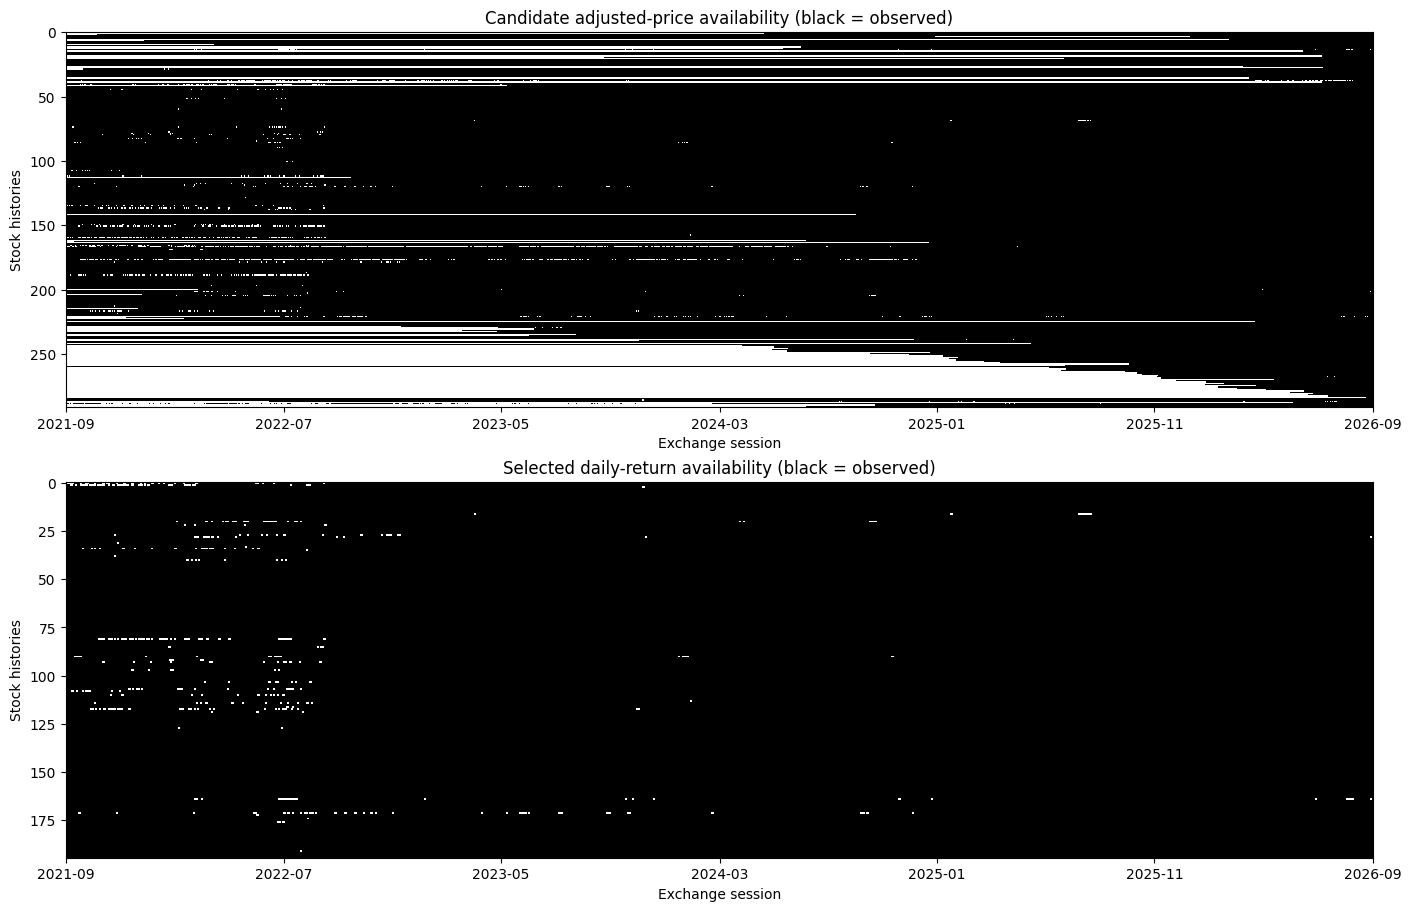

In [4]:
transition_rows = []
for stock_id in candidates:
    component = lineage.loc[lineage["stock_id"].eq(stock_id)].sort_values("first")
    for (_, old), (_, new) in zip(component.iloc[:-1].iterrows(), component.iloc[1:].iterrows()):
        new_rows = clean.loc[(clean["ISIN"].eq(new["ISIN"]))
                             & clean.index.get_level_values("Date").isin(sessions)]
        if new_rows.empty or not (START <= new["first"] <= END):
            continue
        boundary_date = new_rows.index.get_level_values("Date")[0]
        old_rows = clean.loc[clean["ISIN"].eq(old["ISIN"])]
        previous_date = old_rows.index.get_level_values("Date").max() if len(old_rows) else pd.NaT
        old_price = old_rows.iloc[-1]["price"] if len(old_rows) else np.nan
        new_price = new_rows.iloc[0]["price"]
        # Older prices may precede the analysis window; retrieve the last source value.
        if pd.isna(previous_date):
            older = candidate_data.loc[candidate_data["ISIN"].eq(old["ISIN"])]
            previous_date = older["Date"].max()
            vals = older.loc[older["Date"].eq(previous_date), "AdjustedPrice"]
            old_price = vals.iloc[0] if vals.nunique(dropna=False) == 1 else np.nan
        change = new_price / old_price - 1 if np.isfinite(old_price) and old_price > 0 else np.nan
        transition_rows.append({"stock_id": stock_id, "name": audit.loc[stock_id, "name"],
            "old_isin": old["ISIN"], "new_isin": new["ISIN"], "previous_record": previous_date,
            "boundary_date": boundary_date, "old_price": old_price, "new_price": new_price,
            "recorded_change": change, "daily_log_return": all_returns.loc[boundary_date, stock_id],
            "large_change_flag": bool(abs(change) >= BOUNDARY_FLAG),
            "evidence": new["link_evidence"]})
transitions = pd.DataFrame(transition_rows)
display(transitions)

returns = all_returns.loc[:, stock_ids]
prices = prices_in_window.loc[:, stock_ids]
complete_mask = returns.notna().all(axis=1)
complete = returns.loc[complete_mask]
assert len(complete) >= MIN_PAIR, "Too few complete dates for the planned common-panel analysis."
assert complete.std().gt(0).all(), "Review constant stocks before PCA and covariance estimation."


def missing_summary(label: str, p: pd.DataFrame, r: pd.DataFrame) -> dict:
    """Count missing entries with each table's own explicit denominator."""
    return {"sample": label, "stocks": r.shape[1], "dates": len(r),
            "price_cells": p.size, "price_NaNs": int(p.isna().sum().sum()),
            "price_NaN_pct": 100 * p.isna().sum().sum() / p.size,
            "return_cells": r.size, "return_NaNs": int(r.isna().sum().sum()),
            "return_NaN_pct": 100 * r.isna().sum().sum() / r.size}


missingness = pd.DataFrame([
    missing_summary("All candidate histories", prices_in_window, all_returns),
    missing_summary("After boundary/95% filter", prices_in_window[eligible.index], all_returns[eligible.index]),
    missing_summary("After share-class selection", prices, returns),
    missing_summary("Complete dates; same selected stocks", prices.loc[complete_mask], complete),
]).set_index("sample")
display(missingness)
print(f"Complete dates retained: {len(complete):,}/{len(returns):,}; "
      f"removed: {(~complete_mask).sum():,} ({100 * (~complete_mask).mean():.1f}%).")
fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
for ax, frame, title in zip(axes, [prices_in_window, returns],
                          ["Candidate adjusted-price availability", "Selected daily-return availability"]):
    ax.imshow(frame.notna().T, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
    ticks = np.linspace(0, len(frame) - 1, 7).astype(int)
    ax.set_xticks(ticks, frame.index[ticks].strftime("%Y-%m"))
    ax.set(title=title + " (black = observed)", xlabel="Exchange session", ylabel="Stock histories")
plt.show()
plt.close(fig)

## 3. Correlation, covariance, and sector structure

Pearson measures linear same-day co-movement. Spearman measures monotonic association
of return ranks; it gives extreme magnitudes less influence, but is not immune to
data problems. Correlation of absolute log returns examines coincident movement sizes,
regardless of direction. Zero correlation does not establish independence.

[pandas correlation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
uses pairwise complete observations. The available-pair matrices therefore have varying
support and need not be positive semidefinite. The complete panel controls the observation
dates, but conditions results on those retained dates; compare both panels.

[Covariance](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.cov.html)
retains daily log-return scale (squared fractional-return units), unlike correlation.
[Ledoit–Wolf](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.LedoitWolf.html)
shrinks the complete-panel covariance; it does not fix missing data or outliers.

Only unique unordered pairs enter summaries. Unknown sectors are excluded from sector
comparisons. The pair-weighted result compares all internal pairs against all cross-sector
pairs. The equally sector-weighted result averages internal and sector-to-rest means
over sectors with both estimates; small and large sectors then have equal weight.

In [5]:
def dependence_pairs(frame: pd.DataFrame, absolute: bool = True) -> tuple[dict, pd.DataFrame]:
    """Calculate correlation matrices and the exact paired-date support for each pair."""
    matrices = {"pearson": frame.corr(min_periods=MIN_PAIR),
                "spearman": frame.corr(method="spearman", min_periods=MIN_PAIR)}
    if absolute:
        matrices["absolute"] = frame.abs().corr(min_periods=MIN_PAIR)
    observed = frame.notna().to_numpy()
    n_pairs = observed.astype(np.int32).T @ observed.astype(np.int32)
    rows = []
    for i, j in combinations(range(frame.shape[1]), 2):
        a, b = frame.columns[i], frame.columns[j]
        indices = np.flatnonzero(observed[:, i] & observed[:, j])
        row = {"stock_i": a, "stock_j": b, "name_i": selected.loc[a, "name"],
               "name_j": selected.loc[b, "name"], "sector_i": selected.loc[a, "sector"],
               "sector_j": selected.loc[b, "sector"], "n_pair": len(indices),
               "first_date": frame.index[indices[0]] if len(indices) else pd.NaT,
               "last_date": frame.index[indices[-1]] if len(indices) else pd.NaT}
        row.update({metric: matrix.iloc[i, j] for metric, matrix in matrices.items()})
        rows.append(row)
    matrices["n_pair"] = pd.DataFrame(n_pairs, index=frame.columns, columns=frame.columns)
    pairs = pd.DataFrame(rows)
    pairs["known_sectors"] = pairs[["sector_i", "sector_j"]].notna().all(axis=1)
    pairs["same_sector"] = pairs["known_sectors"] & pairs["sector_i"].eq(pairs["sector_j"])
    return matrices, pairs


def sector_summaries(pairs: pd.DataFrame, metrics: list[str], panel: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Compare within/across pairs and give each estimable sector equal macro weight."""
    known = pairs.loc[pairs["known_sectors"]]
    rows, global_rows = [], []
    for metric in metrics:
        local = []
        for sector, stocks in selected.dropna(subset=["sector"]).groupby("sector"):
            internal = known.loc[known["sector_i"].eq(sector) & known["sector_j"].eq(sector), metric].dropna()
            external = known.loc[known["sector_i"].eq(sector) ^ known["sector_j"].eq(sector), metric].dropna()
            local.append({"panel": panel, "metric": metric, "sector": sector, "stocks": len(stocks),
                "within_pairs": len(internal), "between_pairs": len(external),
                "within_mean": internal.mean(), "within_median": internal.median(),
                "between_mean": external.mean(), "between_median": external.median(),
                "difference": internal.mean() - external.mean()})
        rows.extend(local)
        inside = known.loc[known["same_sector"], metric].dropna()
        outside = known.loc[~known["same_sector"], metric].dropna()
        global_rows.append({"panel": panel, "metric": metric, "weighting": "pairs",
            "within_mean": inside.mean(), "between_mean": outside.mean(),
            "difference": inside.mean() - outside.mean(),
            "within_pairs": len(inside), "between_pairs": len(outside)})
        estimable = pd.DataFrame(local).dropna(subset=["within_mean", "between_mean"])
        global_rows.append({"panel": panel, "metric": metric, "weighting": "equal sectors",
            "within_mean": estimable["within_mean"].mean(),
            "between_mean": estimable["between_mean"].mean(),
            "difference": estimable["difference"].mean(), "sectors": len(estimable)})
    return pd.DataFrame(global_rows), pd.DataFrame(rows)


matrices, pair_tables, global_parts, sector_parts = {}, {}, [], []
for label, frame in [("Available pairs", returns), ("Complete dates", complete)]:
    matrices[label], pair_tables[label] = dependence_pairs(frame)
    g, s = sector_summaries(pair_tables[label], ["pearson", "spearman", "absolute"], label)
    global_parts.append(g)
    sector_parts.append(s)
global_comparison = pd.concat(global_parts, ignore_index=True)
sector_comparison = pd.concat(sector_parts, ignore_index=True)
sample_covariances = {"Available pairs": returns.cov(min_periods=MIN_PAIR),
                      "Complete dates": complete.cov()}
lw = LedoitWolf().fit(complete.to_numpy())
shrinkage_covariance = pd.DataFrame(lw.covariance_, index=stock_ids, columns=stock_ids)
display(global_comparison)
with pd.option_context("display.max_rows", None):
    display(sector_comparison)
display(pd.DataFrame({"available_observations": pair_tables["Available pairs"]["n_pair"].describe(),
                      "complete_observations": pair_tables["Complete dates"]["n_pair"].describe()}))
print(f"Ledoit–Wolf shrinkage coefficient: {lw.shrinkage_:.6f}")
display(sample_covariances["Complete dates"].iloc[:8, :8])
display(shrinkage_covariance.iloc[:8, :8])
print("Full pair tables/matrices are retained in pair_tables, matrices, and sample_covariances.")

,panel,metric,weighting,within_mean,between_mean,difference,within_pairs,between_pairs,sectors
0,Available pairs,pearson,pairs,0.112468,0.058997,0.053471,2329.0,16586.0,NaN
1,Available pairs,pearson,equal sectors,0.077794,0.053485,0.024309,NaN,NaN,12.0
2,Available pairs,spearman,pairs,0.124247,0.067466,0.056781,2329.0,16586.0,NaN
3,Available pairs,spearman,equal sectors,0.081000,0.060606,0.020394,NaN,NaN,12.0
4,Available pairs,absolute,pairs,0.059706,0.030658,0.029048,2329.0,16586.0,NaN
5,Available pairs,absolute,equal sectors,0.047958,0.028254,0.019704,NaN,NaN,12.0
6,Complete dates,pearson,pairs,0.099286,0.049210,0.050076,2329.0,16586.0,NaN
7,Complete dates,pearson,equal sectors,0.059337,0.043763,0.015574,NaN,NaN,12.0
8,Complete dates,spearman,pairs,0.112901,0.057542,0.055359,2329.0,16586.0,NaN
9,Complete dates,spearman,equal sectors,0.071496,0.051111,0.020385,NaN,NaN,12.0


,panel,metric,sector,stocks,within_pairs,between_pairs,within_mean,within_median,between_mean,between_median,difference
0,Available pairs,pearson,Bank,2,1,386,0.063144,0.063144,0.019001,0.019267,0.044144
1,Available pairs,pearson,Basic Materials,12,66,2196,0.063055,0.032907,0.060399,0.044526,0.002656
2,Available pairs,pearson,Consumer Discretionary,11,55,2024,0.051718,0.037567,0.053675,0.044380,-0.001957
3,Available pairs,pearson,Consumer Staples,21,210,3654,0.088982,0.034981,0.045676,0.037647,0.043306
4,Available pairs,pearson,Energy,35,595,5600,0.169501,0.126734,0.062575,0.053133,0.106926
5,Available pairs,pearson,Financials,30,435,4950,0.128574,0.094095,0.071570,0.059409,0.057004
6,Available pairs,pearson,Health Care,13,78,2366,0.028162,0.029222,0.038329,0.034503,-0.010167
7,Available pairs,pearson,Industrials,38,703,5966,0.091175,0.078436,0.067478,0.058872,0.023697
8,Available pairs,pearson,Real Estate,4,6,764,0.066316,0.042168,0.058787,0.051659,0.007528
9,Available pairs,pearson,Technology,18,153,3186,0.071183,0.058083,0.057903,0.051141,0.013280


,available_observations,complete_observations
count,18915.000000,18915.0
mean,1248.214909,871.0
std,19.802463,0.0
min,1087.000000,871.0
25%,1253.000000,871.0
50%,1257.000000,871.0
75%,1257.000000,871.0
max,1257.000000,871.0


Ledoit–Wolf shrinkage coefficient: 0.488020


stock_id,NO0010636491,NO0010808405,SE0015193412,NO0010950249,NO0010657505,NO0010963275,NO0010816093,NO0010907744
stock_id,,,,,,,,
NO0010636491,0.000330,-0.000009,0.000039,0.000029,0.000017,-0.000023,-0.000002,-0.000041
NO0010808405,-0.000009,0.000244,-0.000050,0.000004,0.000005,-0.000012,0.000006,0.000006
SE0015193412,0.000039,-0.000050,0.003529,-0.000002,0.000005,0.000014,-0.000002,0.000098
NO0010950249,0.000029,0.000004,-0.000002,0.002602,0.000019,0.000112,0.000048,0.000026
NO0010657505,0.000017,0.000005,0.000005,0.000019,0.000231,-0.000015,0.000066,-0.000011
NO0010963275,-0.000023,-0.000012,0.000014,0.000112,-0.000015,0.002706,0.000073,-0.000019
NO0010816093,-0.000002,0.000006,-0.000002,0.000048,0.000066,0.000073,0.000498,0.000004
NO0010907744,-0.000041,0.000006,0.000098,0.000026,-0.000011,-0.000019,0.000004,0.006095


,NO0010636491,NO0010808405,SE0015193412,NO0010950249,NO0010657505,NO0010963275,NO0010816093,NO0010907744
NO0010636491,8.879386e-04,-0.000005,1.981583e-05,1.506850e-05,0.000009,-0.000012,-7.824378e-07,-0.000021
NO0010808405,-4.672992e-06,0.000844,-2.558658e-05,1.907326e-06,0.000003,-0.000006,2.925478e-06,0.000003
SE0015193412,1.981583e-05,-0.000026,2.524213e-03,-8.145920e-07,0.000002,0.000007,-1.170200e-06,0.000050
NO0010950249,1.506850e-05,0.000002,-8.145920e-07,2.050169e-03,0.000010,0.000057,2.449283e-05,0.000013
NO0010657505,8.718850e-06,0.000003,2.488562e-06,9.760081e-06,0.000838,-0.000008,3.372193e-05,-0.000006
NO0010963275,-1.161630e-05,-0.000006,7.387545e-06,5.739164e-05,-0.000008,0.002103,3.745408e-05,-0.000010
NO0010816093,-7.824378e-07,0.000003,-1.170200e-06,2.449283e-05,0.000034,0.000037,9.741726e-04,0.000002
NO0010907744,-2.076348e-05,0.000003,4.992180e-05,1.339013e-05,-0.000006,-0.000010,1.815401e-06,0.003836


Full pair tables/matrices are retained in pair_tables, matrices, and sample_covariances.


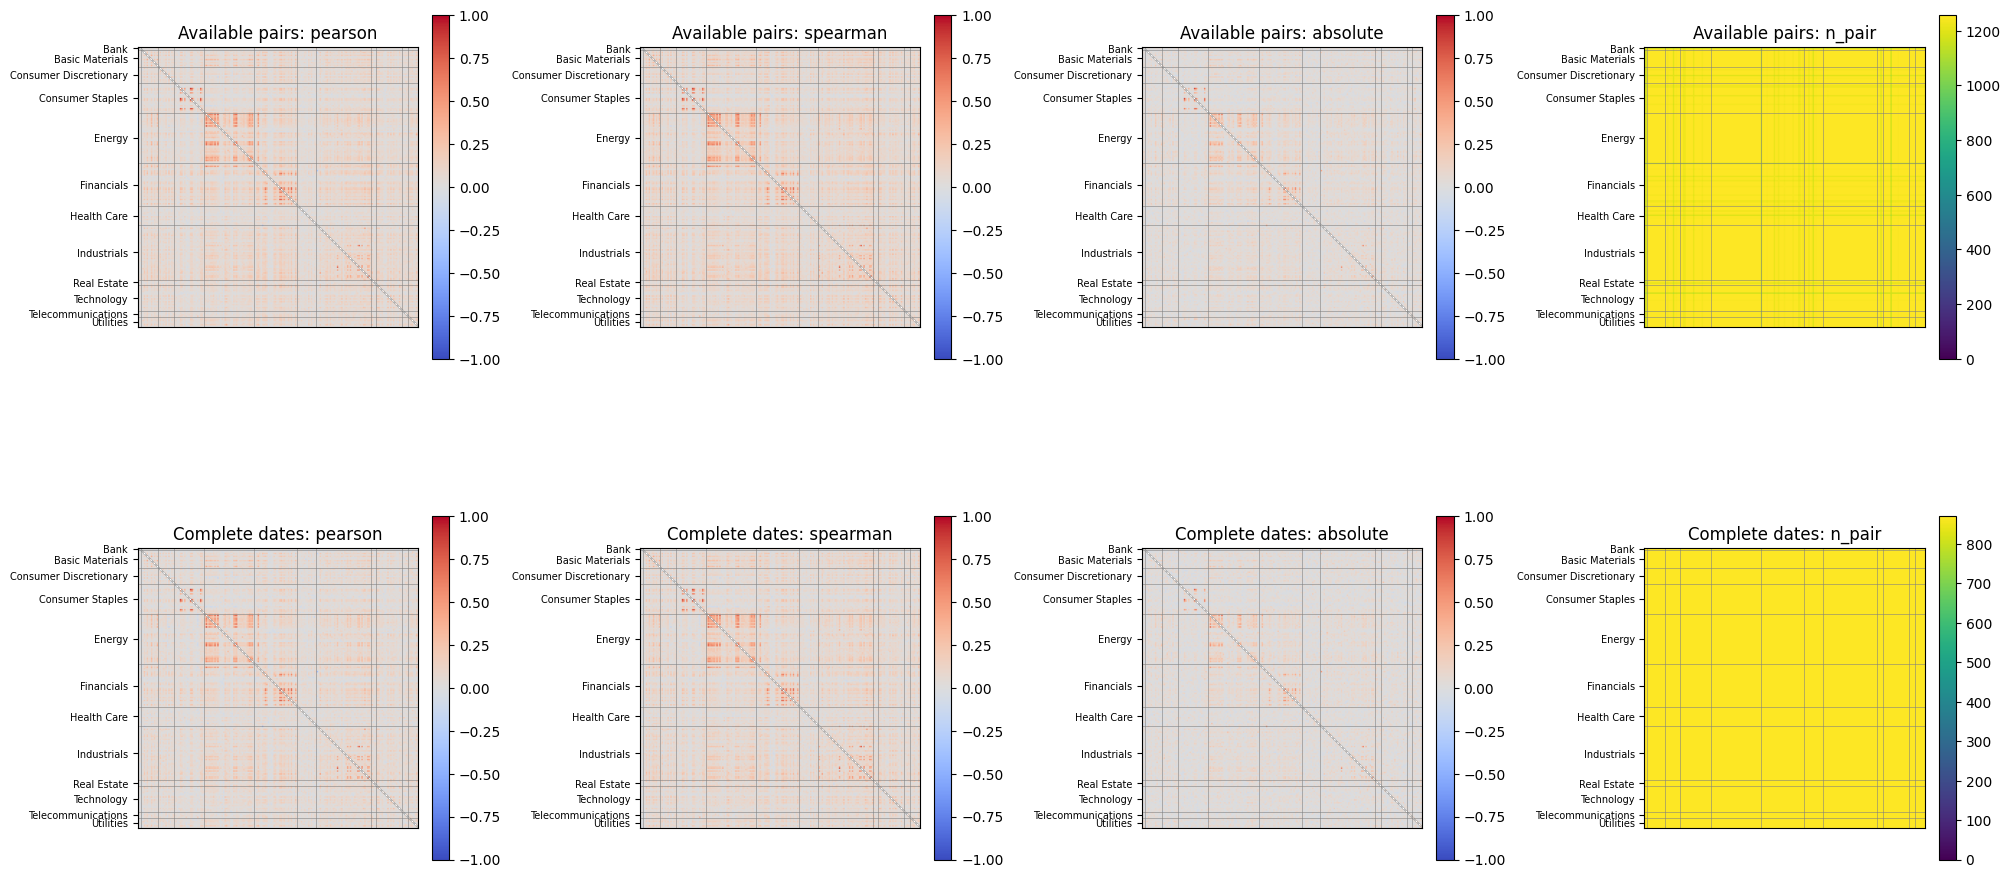

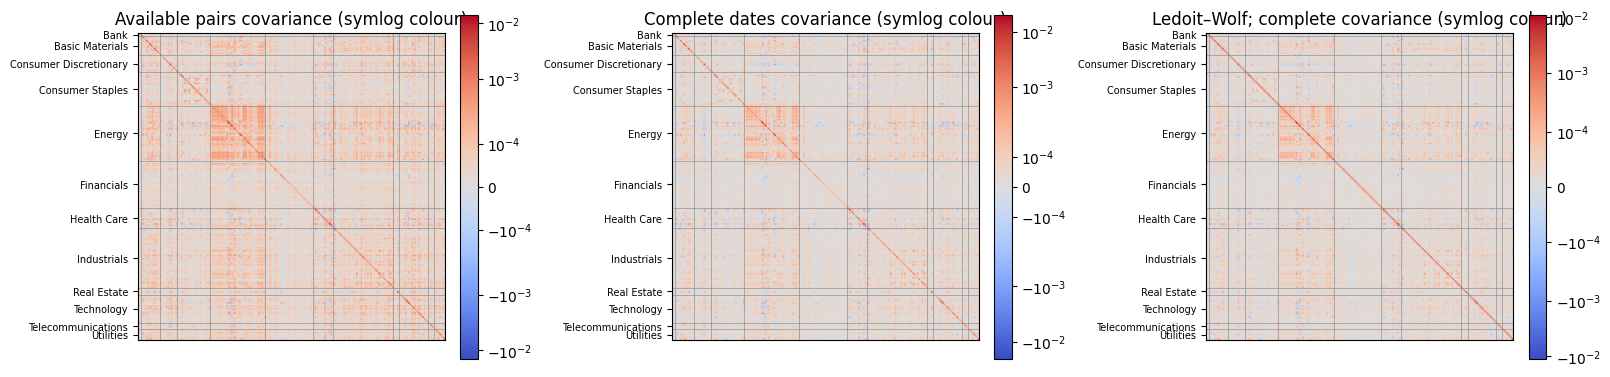

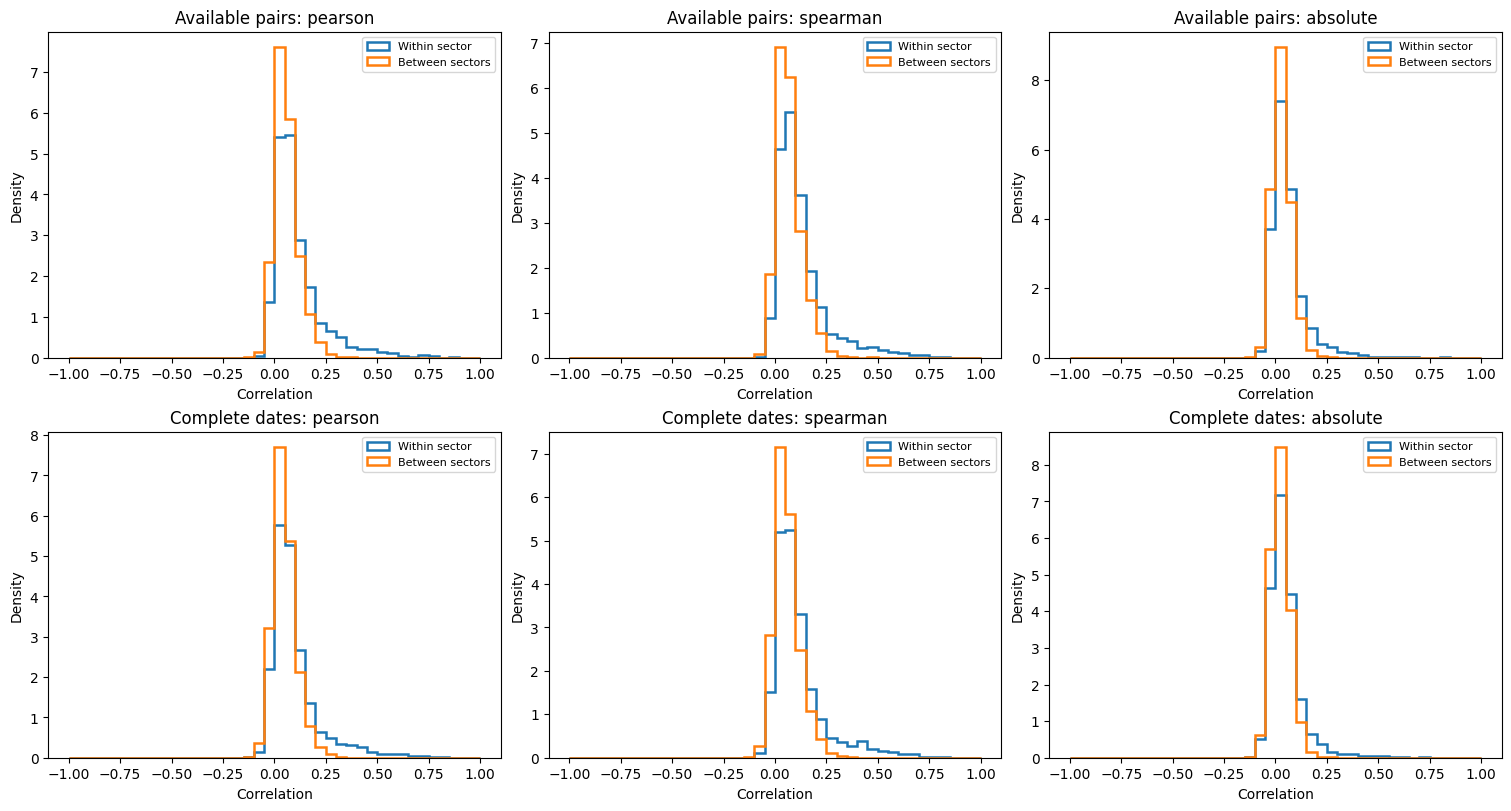

In [6]:
sector_labels = selected["sector"].fillna("Unknown").to_numpy()
boundaries = np.flatnonzero(sector_labels[1:] != sector_labels[:-1]) + 1
starts = np.r_[0, boundaries]
ends = np.r_[boundaries, len(stock_ids)]


def sector_axes(ax: plt.Axes) -> None:
    """Mark the fixed sector ordering shared by all stock matrices."""
    for boundary in boundaries:
        ax.axhline(boundary - 0.5, color="grey", linewidth=0.4)
        ax.axvline(boundary - 0.5, color="grey", linewidth=0.4)
    ax.set_yticks((starts + ends - 1) / 2, sector_labels[starts], fontsize=7)
    ax.set_xticks([])


fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for row, label in enumerate(matrices):
    for col, metric in enumerate(["pearson", "spearman", "absolute", "n_pair"]):
        matrix = matrices[label][metric].copy()
        if metric != "n_pair":
            np.fill_diagonal(matrix.values, np.nan)
        im = axes[row, col].imshow(matrix, cmap="viridis" if metric == "n_pair" else "coolwarm",
                                   vmin=0 if metric == "n_pair" else -1,
                                   vmax=None if metric == "n_pair" else 1)
        axes[row, col].set_title(f"{label}: {metric}")
        sector_axes(axes[row, col])
        fig.colorbar(im, ax=axes[row, col], shrink=0.7)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, (label, matrix) in zip(axes, [*sample_covariances.items(), ("Ledoit–Wolf; complete", shrinkage_covariance)]):
    scale = np.nanmax(np.abs(matrix.to_numpy()))
    im = ax.imshow(matrix, cmap="coolwarm", norm=SymLogNorm(linthresh=scale / 100, vmin=-scale, vmax=scale))
    ax.set_title(label + " covariance (symlog colour)")
    sector_axes(ax)
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for row, (label, pairs) in enumerate(pair_tables.items()):
    for ax, metric in zip(axes[row], ["pearson", "spearman", "absolute"]):
        for same, name in [(True, "Within sector"), (False, "Between sectors")]:
            values = pairs.loc[pairs["known_sectors"] & pairs["same_sector"].eq(same), metric].dropna()
            ax.hist(values, bins=np.linspace(-1, 1, 41), density=True, histtype="step", linewidth=1.8, label=name)
        ax.set(title=f"{label}: {metric}", xlabel="Correlation", ylabel="Density")
        ax.legend(fontsize=8)
plt.show()
plt.close(fig)

## 4. Uncertainty in the sector differences

Stock pairs share companies and are not independent replicates. Circular block
resampling draws consecutive session blocks jointly across every stock. Complete-date
selection happens **after** resampling the original grid, so discarded sessions are
not compressed before building blocks. Pearson and Spearman are recalculated, including
ranks and bootstrap ties, for every draw.

The intervals below are percentile intervals conditional on this selected stock universe
and its missingness. They do not incorporate uncertainty in identity mappings or issuer
selection. Block lengths 5, 20 (primary), and 63 assess sensitivity to temporal dependence.
Circular wrapping and an approximately stable dependence structure within this five-year
period are resampling assumptions; intervals are not causal evidence or multiplicity-adjusted tests.

Bootstrap block 5: completed 1,000 draws


Bootstrap block 20: completed 1,000 draws


Bootstrap block 63: completed 1,000 draws


Bootstrap runtime: 67.8 seconds


,block_sessions,metric,group,difference,lower_95,upper_95,valid_draws,requested_draws
28,20,pearson,All pairs,0.050076,0.045622,0.056134,1000,1000
29,20,pearson,Bank,-0.042175,-0.121508,0.029016,1000,1000
30,20,pearson,Basic Materials,0.003661,-0.006389,0.015399,1000,1000
31,20,pearson,Consumer Discretionary,-0.009671,-0.018916,0.000154,1000,1000
32,20,pearson,Consumer Staples,0.040630,0.031866,0.051917,1000,1000
33,20,pearson,Energy,0.098127,0.083396,0.115543,1000,1000
34,20,pearson,Financials,0.052914,0.041824,0.065301,1000,1000
35,20,pearson,Health Care,-0.011227,-0.020943,-0.003241,1000,1000
36,20,pearson,Industrials,0.024522,0.019167,0.033262,1000,1000
37,20,pearson,Real Estate,0.018731,-0.006542,0.043269,1000,1000


,block_sessions,metric,group,difference,lower_95,upper_95,valid_draws,requested_draws
0,5,pearson,All pairs,0.050076,0.045401,0.056346,1000,1000
13,5,pearson,Equal sectors,0.015574,0.007559,0.023210,1000,1000
14,5,spearman,All pairs,0.055359,0.050931,0.060039,1000,1000
27,5,spearman,Equal sectors,0.020385,0.012546,0.027597,1000,1000
28,20,pearson,All pairs,0.050076,0.045622,0.056134,1000,1000
41,20,pearson,Equal sectors,0.015574,0.007948,0.023042,1000,1000
42,20,spearman,All pairs,0.055359,0.050545,0.060347,1000,1000
55,20,spearman,Equal sectors,0.020385,0.013023,0.026938,1000,1000
56,63,pearson,All pairs,0.050076,0.045015,0.056527,1000,1000
69,63,pearson,Equal sectors,0.015574,0.007933,0.023320,1000,1000


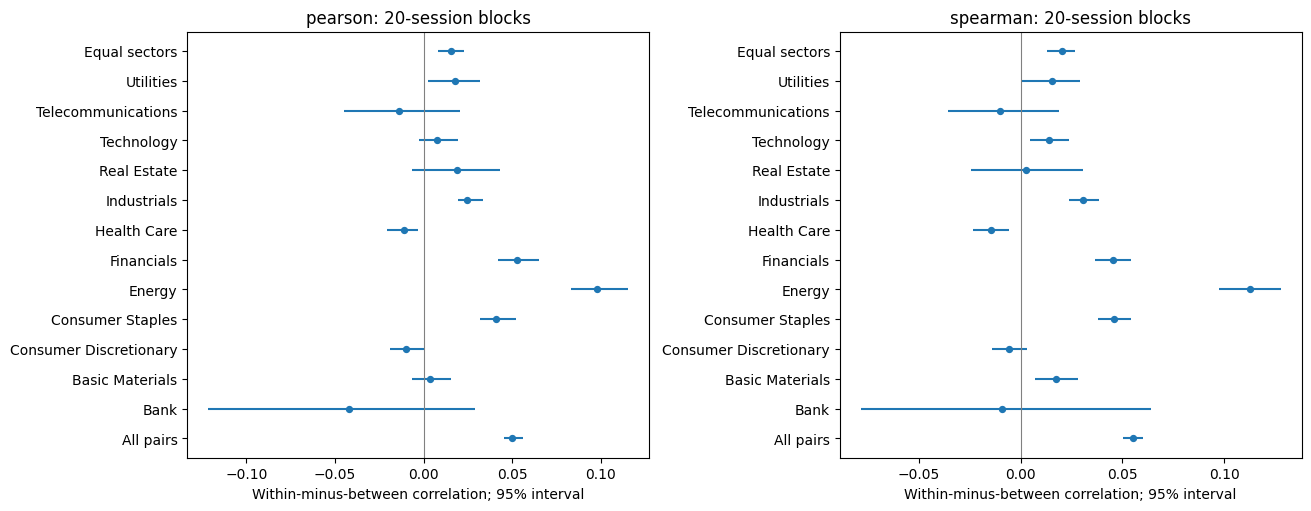

In [7]:
upper_i, upper_j = np.triu_indices(len(stock_ids), 1)
pair_order = pair_tables["Complete dates"]
known_pair = pair_order["known_sectors"].to_numpy()
same_pair = pair_order["same_sector"].to_numpy()
sector_names = sorted(selected["sector"].dropna().unique())
group_masks = {"All pairs": (known_pair & same_pair, known_pair & ~same_pair)}
for sector in sector_names:
    a = pair_order["sector_i"].eq(sector).to_numpy()
    b = pair_order["sector_j"].eq(sector).to_numpy()
    group_masks[sector] = (known_pair & a & b, known_pair & (a ^ b))


def correlation_array(values: np.ndarray) -> np.ndarray:
    """Pearson matrix with undefined constant-series entries left missing."""
    centered = values - values.mean(axis=0)
    norms = np.sqrt((centered ** 2).sum(axis=0))
    denominator = norms[:, None] * norms[None, :]
    return np.divide(centered.T @ centered, denominator,
                     out=np.full(denominator.shape, np.nan), where=denominator > 0)


def correlation_differences(values: np.ndarray) -> np.ndarray:
    """Global, per-sector, and equal-sector within-minus-between differences."""
    rows = []
    for sample in [values, stats.rankdata(values, axis=0, method="average")]:
        correlations = correlation_array(sample)[upper_i, upper_j]
        differences = []
        for inside, outside in group_masks.values():
            x, y = correlations[inside], correlations[outside]
            differences.append(np.nanmean(x) - np.nanmean(y) if len(x) and len(y) else np.nan)
        differences.append(np.nanmean(differences[1:]))
        rows.append(differences)
    return np.asarray(rows)


def bootstrap_differences(frame: pd.DataFrame, block: int, draws: int, seed: int) -> np.ndarray:
    """Resample full-grid circular blocks, then retain complete sampled observations."""
    rng = np.random.default_rng(seed)
    values = frame.to_numpy()
    result = np.full((draws, 2, len(group_masks) + 1), np.nan)
    with threadpool_limits(limits=1):
        for draw in range(draws):
            starts = rng.integers(0, len(values), size=int(np.ceil(len(values) / block)))
            indices = ((starts[:, None] + np.arange(block)) % len(values)).ravel()[:len(values)]
            sampled = values[indices]
            sampled = sampled[np.isfinite(sampled).all(axis=1)]
            if len(sampled) >= MIN_PAIR:
                result[draw] = correlation_differences(sampled)
    return result


bootstrap_samples, bootstrap_rows = {}, []
point_differences = correlation_differences(complete.to_numpy())
group_names = [*group_masks, "Equal sectors"]
bootstrap_started = perf_counter()
for block in BOOT_BLOCKS:
    draws = bootstrap_differences(returns, block, BOOT_DRAWS, SEED)
    bootstrap_samples[block] = draws
    for m, metric in enumerate(["pearson", "spearman"]):
        for k, group in enumerate(group_names):
            observed = draws[:, m, k]
            observed = observed[np.isfinite(observed)]
            low, high = np.quantile(observed, [0.025, 0.975]) if len(observed) else (np.nan, np.nan)
            bootstrap_rows.append({"block_sessions": block, "metric": metric, "group": group,
                "difference": point_differences[m, k], "lower_95": low, "upper_95": high,
                "valid_draws": len(observed), "requested_draws": BOOT_DRAWS})
    print(f"Bootstrap block {block}: completed {BOOT_DRAWS:,} draws", flush=True)
bootstrap_ci = pd.DataFrame(bootstrap_rows)
print(f"Bootstrap runtime: {perf_counter() - bootstrap_started:.1f} seconds")
display(bootstrap_ci.loc[bootstrap_ci["block_sessions"].eq(20)])
display(bootstrap_ci.loc[bootstrap_ci["group"].isin(["All pairs", "Equal sectors"])])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, metric in zip(axes, ["pearson", "spearman"]):
    table = bootstrap_ci.loc[bootstrap_ci["block_sessions"].eq(20) & bootstrap_ci["metric"].eq(metric)].dropna(subset=["lower_95"])
    ax.hlines(table["group"], table["lower_95"], table["upper_95"])
    ax.scatter(table["difference"], table["group"], s=18)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set(title=f"{metric}: 20-session blocks", xlabel="Within-minus-between correlation; 95% interval")
plt.show()
plt.close(fig)

## 5. Rolling dependence and fixed lead/lag relationships

Rolling windows use consecutive sessions on the original grid. A pair contributes only
when both stocks are observed on every session of that window. Changing contributing
pairs can change averages, so their counts are plotted alongside correlations. The
sector gap is unavailable if no within-sector or between-sector pairs contribute.

For lag \(k\), calculate \(\mathrm{Corr}(r_{i,t},r_{j,t+k})\). Positive \(k\) means
stock \(i\) precedes stock \(j\); zero is contemporaneous. Pair orientation is the
fixed stock-column order. Nonzero-lag results are descriptive, involve many comparisons,
and do not by themselves establish predictability or causality.

,available_differences,median_difference,minimum_difference,maximum_difference,mean_within_pairs,mean_between_pairs
window,,,,,,
63,1195,0.055186,0.029443,0.087720,2128.776452,14887.485282
252,1006,0.053314,0.040280,0.075398,1733.826571,11845.837709


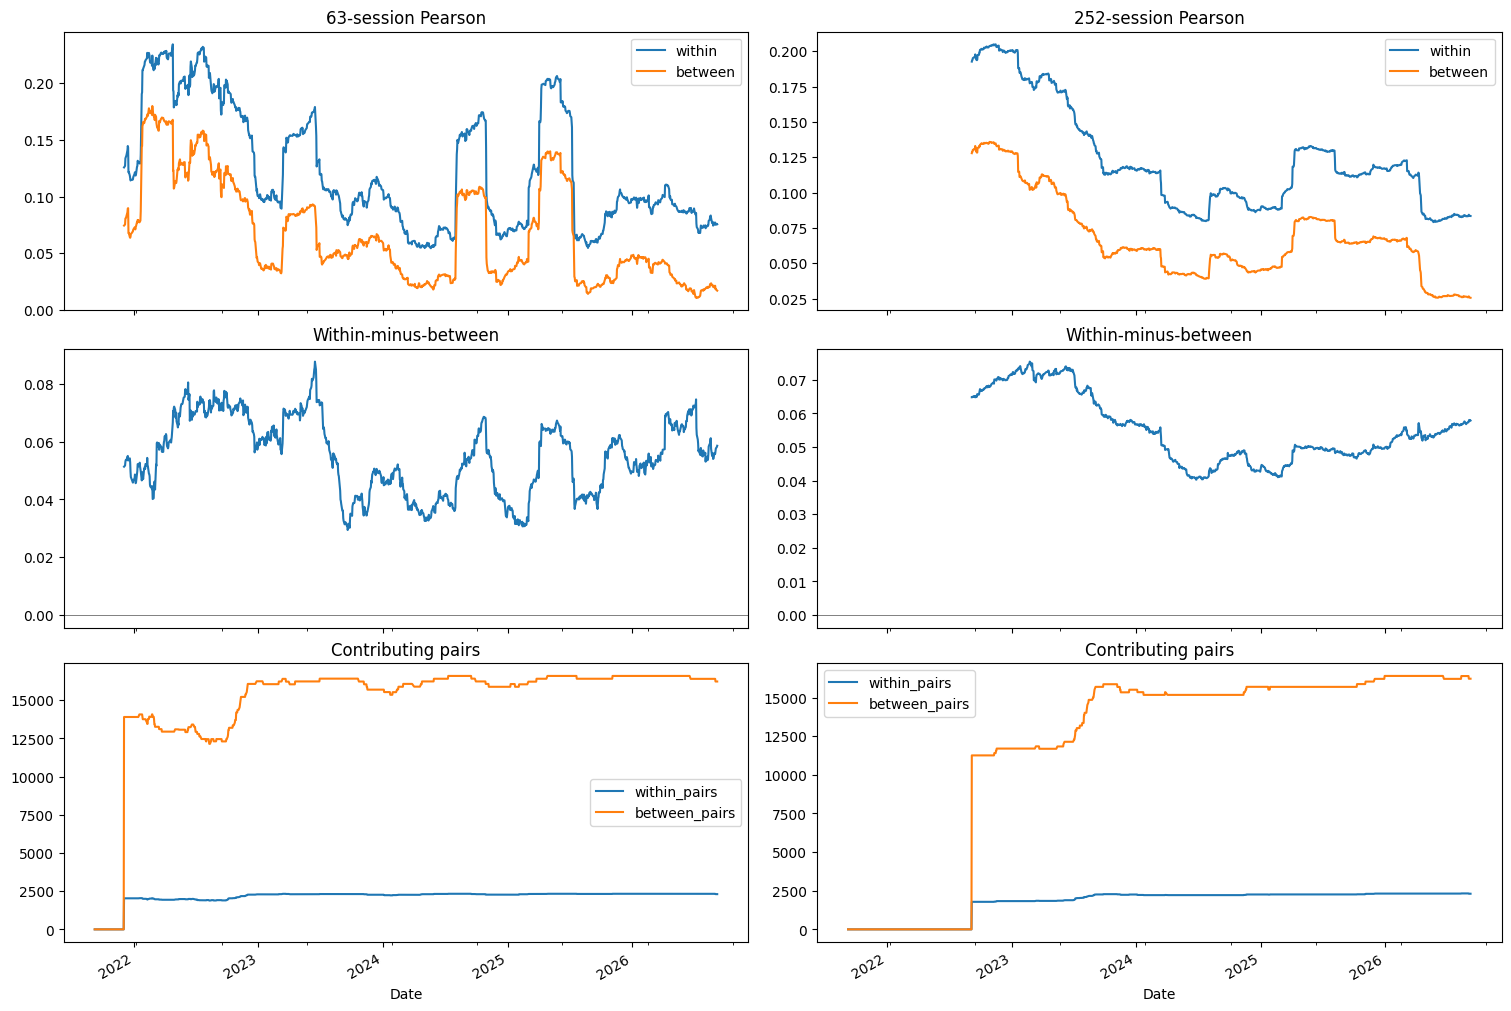

mean_correlation  contributing_pairs
lag same_sector                                      
-5  False               -0.000069               16586
    True                -0.000722                2329
-4  False                0.001546               16586
    True                 0.004136                2329
-3  False                0.002084               16586
    True                 0.004347                2329
-2  False               -0.002811               16586
    True                -0.004256                2329
-1  False                0.006083               16586
    True                 0.011632                2329
 0  False                0.058997               16586
    True                 0.112468                2329
 1  False                0.005007               16586
    True                 0.008622                2329
 2  False               -0.003483               16586
    True                -0.002355                2329
 3  False                0.002527               16586
    True                 0.002166                2329
 4  False                0.002168               16586
    True                 0.003802                2329
 5  False               -0.000431               16586
    True                 0.000946                2329

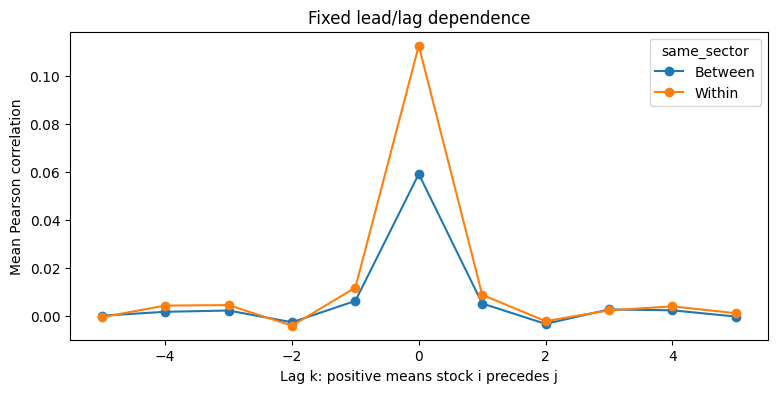

Largest absolute nonzero-lag estimates (exploratory):


,stock_i,stock_j,known_sectors,same_sector,lag,n_pair,correlation,abs_correlation
179833,NO0012953720,NO0010931207,True,False,4,1253,-0.467374,0.467374
141873,NO0012953720,NO0010917339,True,True,2,1255,-0.310517,0.310517
85324,NO0010892359,BMG9156K1018,True,False,-1,1256,0.289714,0.289714
129935,BMG9156K1018,NO0010931918,True,True,1,1256,0.287969,0.287969
54291,BMG9156K1018,NO0012470089,True,True,-3,1254,-0.270927,0.270927
47308,NO0012953720,NO0003053308,True,True,-3,1254,0.255547,0.255547
144876,NO0010358484,NL0015268814,True,False,2,1255,-0.244406,0.244406
142934,NO0010917339,NO0010931207,True,False,2,1255,0.203709,0.203709
89554,NO0010397581,BMG9156K1018,True,False,-1,1256,-0.196524,0.196524
161050,NO0010892359,NO0010815673,True,False,3,1254,-0.180737,0.180737


In [8]:
rolling_parts = []
for window in (63, 252):
    internal_sum, external_sum = np.zeros(len(returns)), np.zeros(len(returns))
    internal_n, external_n = np.zeros(len(returns), dtype=int), np.zeros(len(returns), dtype=int)
    for row in pair_tables["Available pairs"].itertuples():
        if not row.known_sectors:
            continue
        a, b = returns[row.stock_i], returns[row.stock_j]
        corr = a.rolling(window, min_periods=window).corr(b).to_numpy()
        valid = (a.notna() & b.notna()).rolling(window, min_periods=window).sum().eq(window).to_numpy()
        valid &= np.isfinite(corr)
        sums, counts = (internal_sum, internal_n) if row.same_sector else (external_sum, external_n)
        sums[valid] += corr[valid]
        counts[valid] += 1
    inside = np.divide(internal_sum, internal_n, out=np.full(len(returns), np.nan), where=internal_n > 0)
    outside = np.divide(external_sum, external_n, out=np.full(len(returns), np.nan), where=external_n > 0)
    rolling_parts.append(pd.DataFrame({"Date": sessions, "window": window, "within": inside,
        "between": outside, "difference": inside - outside,
        "within_pairs": internal_n, "between_pairs": external_n}))
rolling_summary = pd.concat(rolling_parts, ignore_index=True)
display(rolling_summary.groupby("window").agg(
    available_differences=("difference", "count"), median_difference=("difference", "median"),
    minimum_difference=("difference", "min"), maximum_difference=("difference", "max"),
    mean_within_pairs=("within_pairs", "mean"), mean_between_pairs=("between_pairs", "mean")))
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex="col", constrained_layout=True)
for col, window in enumerate((63, 252)):
    part = rolling_summary.loc[rolling_summary["window"].eq(window)].set_index("Date")
    part[["within", "between"]].plot(ax=axes[0, col], title=f"{window}-session Pearson")
    part["difference"].plot(ax=axes[1, col], title="Within-minus-between")
    axes[1, col].axhline(0, color="grey", linewidth=0.7)
    part[["within_pairs", "between_pairs"]].plot(ax=axes[2, col], title="Contributing pairs")
plt.show()
plt.close(fig)

lag_parts = []
for lag in range(-5, 6):
    shifted = returns.shift(-lag)
    a, b = returns.to_numpy(), shifted.to_numpy()
    ma, mb = np.isfinite(a).astype(float), np.isfinite(b).astype(float)
    a, b = np.nan_to_num(a), np.nan_to_num(b)
    # Matrix sums use each pair's actual overlapping observations.
    with threadpool_limits(limits=1):
        n = ma.T @ mb
        sx, sy = a.T @ mb, ma.T @ b
        safe_n = np.maximum(n, 1)
        covariance = a.T @ b - sx * sy / safe_n
        vx = (a * a).T @ mb - sx * sx / safe_n
        vy = ma.T @ (b * b) - sy * sy / safe_n
    denominator = np.sqrt(np.maximum(vx, 0) * np.maximum(vy, 0))
    corr = np.divide(covariance, denominator, out=np.full(n.shape, np.nan),
                     where=(n >= MIN_PAIR) & (denominator > 0))
    part = pair_tables["Available pairs"][["stock_i", "stock_j", "known_sectors", "same_sector"]].copy()
    part["lag"], part["n_pair"], part["correlation"] = lag, n[upper_i, upper_j].astype(int), corr[upper_i, upper_j]
    lag_parts.append(part)
lag_pairs = pd.concat(lag_parts, ignore_index=True)
lag_summary = lag_pairs.loc[lag_pairs["known_sectors"]].groupby(["lag", "same_sector"]).agg(
    mean_correlation=("correlation", "mean"), contributing_pairs=("correlation", "count"))
display(lag_summary)
fig, ax = plt.subplots(figsize=(9, 4))
lag_summary["mean_correlation"].unstack("same_sector").rename(columns={False: "Between", True: "Within"}).plot(ax=ax, marker="o")
ax.set(xlabel="Lag k: positive means stock i precedes j", ylabel="Mean Pearson correlation", title="Fixed lead/lag dependence")
plt.show()
plt.close(fig)
print("Largest absolute nonzero-lag estimates (exploratory):")
display(lag_pairs.loc[lag_pairs["lag"].ne(0)].assign(abs_correlation=lambda x: x.correlation.abs()).nlargest(15, "abs_correlation"))

### 5a. Zoom in on shared market shocks

Each column below links **20-session rolling correlations** (top) with the
**median daily simple return of observed selected stocks** (bottom).
Red dashed lines mark selected shock dates; grey dotted lines mark the sessions
when those observations leave the trailing window. A shock can therefore affect
the estimate for roughly one trading month, even if markets recover sooner. Correlation
cannot be estimated from one day's return pair: the top curves always use windows.
The daily median describes the typical observed stock and limits the influence of
extreme individual returns. It is **not OSEBX**; observed-stock membership varies.
The correlation curves use the same full-window support rule as section 5, now over
20 sessions. Contributing pairs can still change. Shorter windows react faster but
produce noisier estimates, and a few shared extreme returns can dominate them.

The table compares correlations in the 20-session window **ending on the final
highlighted date** of each episode, using the **same stocks** with and without the
highlighted observations. Each original sample has 20 consecutive sessions and no
missing returns in participating stocks. Omitting
shock dates reduces the number of observations; it does not fill gaps or change
the main analysis. `primary_day_down_pct` is the percentage of observed selected
stocks with negative returns on the episode's primary date. These dates were chosen
after inspecting the series: this is a descriptive sensitivity check, not a causal
test or an unbiased estimate of a typical event effect. The smaller late-2023 bump
is omitted because no single dominant shock was isolated.

Historical context checked for these episodes:

- **24 January 2022:** [E24](https://e24.no/boers-og-finans/i/G38JVm/oslo-boers-faller-forsiktig-fra-start)
  reports broad selling, rate concerns and Russia–Ukraine tensions. This date precedes
  the invasion; the 20-session sensitivity window ends on 24 January.
- **13–16 June 2022:** [Norges Bank's June assessment](https://www.norges-bank.no/en/topics/Monetary-policy/Monetary-policy-meetings/2022/june-2022/?tab=122929)
  describes higher inflation, faster expected policy tightening and falling global equities.
- **23–28 September 2022:** [contemporary reporting](https://www.bt.no/nyheter/okonomi/i/8JBjnE/venter-flat-aapning-paa-oslo-boers)
  describes rate and recession fears on 23 September; the
  [government's aquaculture-tax proposal](https://www.regjeringen.no/no/aktuelt/grunnrenteskatt-pa-havbruk/id2929113/)
  was announced on 28 September, when [seafood shares fell sharply](https://www.bt.no/nyheter/okonomi/i/15714X/venter-nedgang-paa-oslo-boers).
- **13–15 March 2023:** [Norges Bank](https://www.norges-bank.no/en/news-events/publications/Financial-Stability-report/2023-1-finansiell-stabilitet/web-report-2023-1-financial-stability/)
  documents the SVB and Credit Suisse turmoil and international market volatility.
- **2–5 August 2024:** [BIS](https://www.bis.org/publications/qr-202409/carry-off-carry-on)
  connects the sell-off to US labour-market news and unwinding leveraged positions.
- **3–10 April 2025:** [Norges Bank](https://www.norges-bank.no/en/news-events/publications/Financial-Stability-report/2025-1-financial-stability/web-report-2025-1-financial-stability/)
  describes tariff announcements, countermeasures and large Norwegian market movements.
- **8 April 2026:** [NTB/Aftenposten](https://www.aftenposten.no/okonomi/i/JOror7/kraftig-fall-paa-oslo-boers-ned-28-prosent)
  reports an Iran ceasefire, falling oil prices and divergent oil-stock/airline reactions.

Event labels describe plausible context; timing and sensitivity alone do not establish
that a named event caused the entire correlation peak. Shared rallies can also raise
correlation, and sector-specific shocks need not increase between-sector correlation.


,episode,window_start,window_end,omitted_dates,stocks,dates_after_omission,within_all,within_without_shocks,between_all,between_without_shocks,primary_day_down_pct
0,2022: rate fears and Ukraine tensions,2021-12-27,2022-01-24,2022-01-24,188,19,0.310,0.172,0.258,0.109,95.876
1,2022: inflation and rate repricing,2022-05-18,2022-06-16,"2022-06-13, 2022-06-16",183,18,0.219,0.117,0.138,0.055,80.208
2,2022: rate fears and salmon-tax proposal,2022-09-01,2022-09-28,"2022-09-23, 2022-09-28",190,18,0.234,0.203,0.154,0.129,82.564
3,2023: SVB and Credit Suisse turmoil,2023-02-16,2023-03-15,"2023-03-13, 2023-03-15",195,18,0.218,0.106,0.141,0.054,84.615
4,2024: global August sell-off,2024-07-09,2024-08-05,"2024-08-02, 2024-08-05",195,18,0.264,0.050,0.209,0.023,84.615
5,2025: tariff shock,2025-03-14,2025-04-10,"2025-04-03, 2025-04-04, 2025-04-09, 2025-04-10",195,16,0.299,0.137,0.215,0.091,85.128
6,2026: ceasefire and oil-price reversal,2026-03-09,2026-04-08,2026-04-08,195,19,0.137,0.114,0.044,0.048,34.359


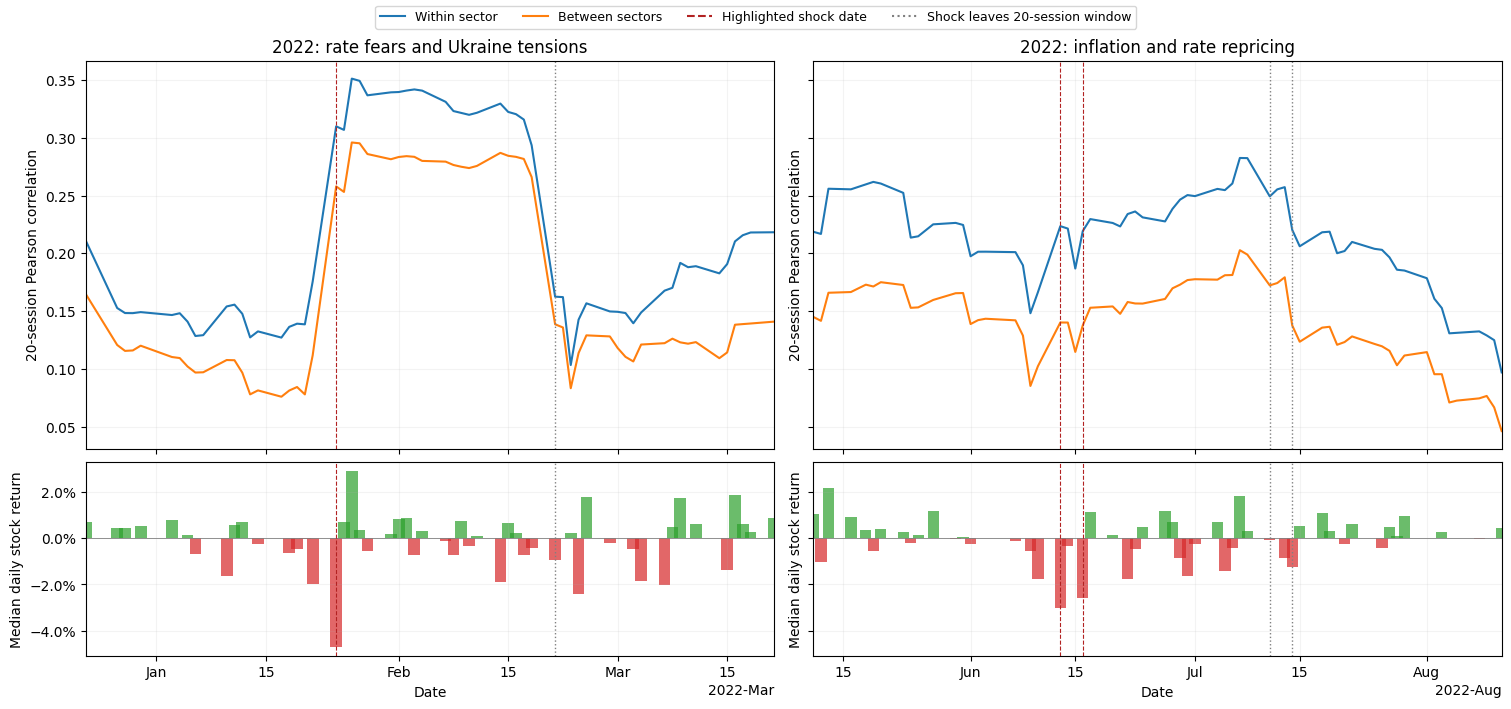

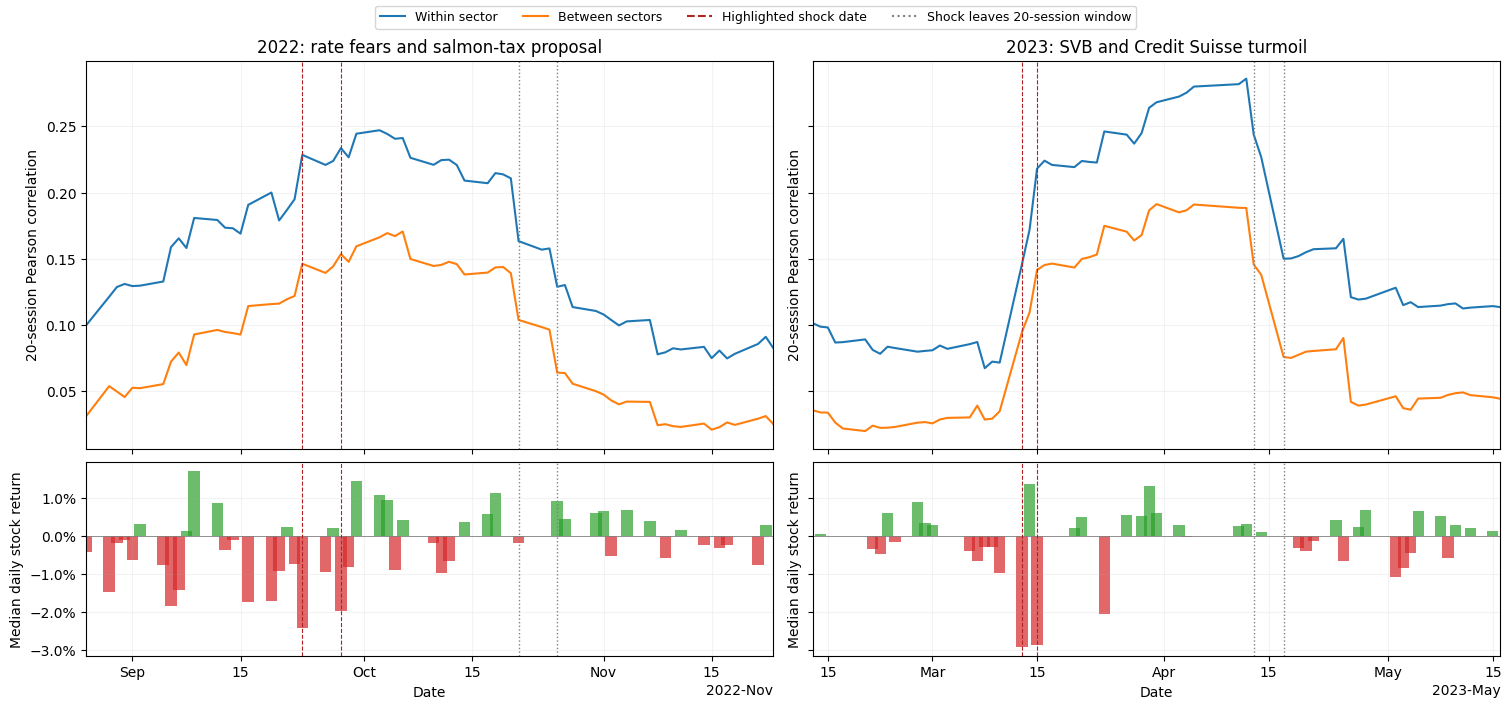

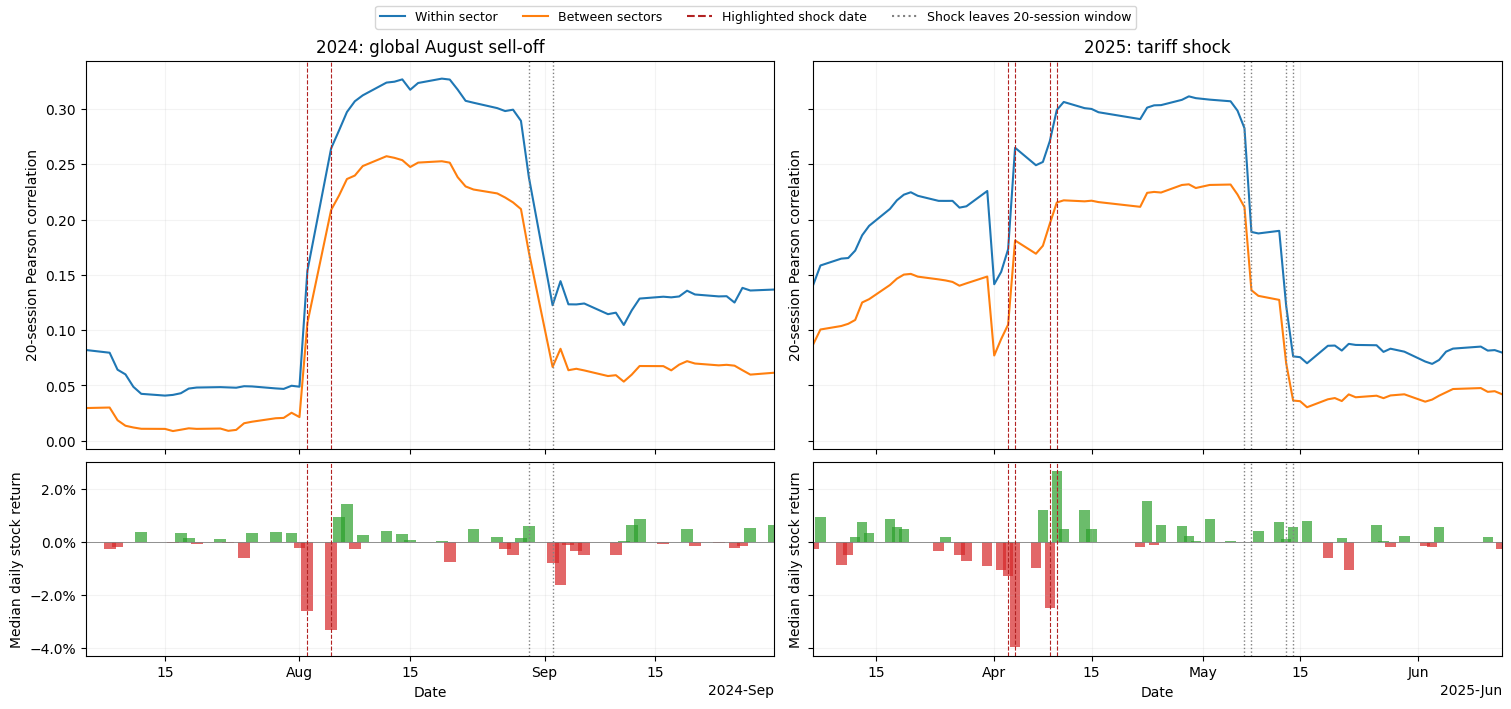

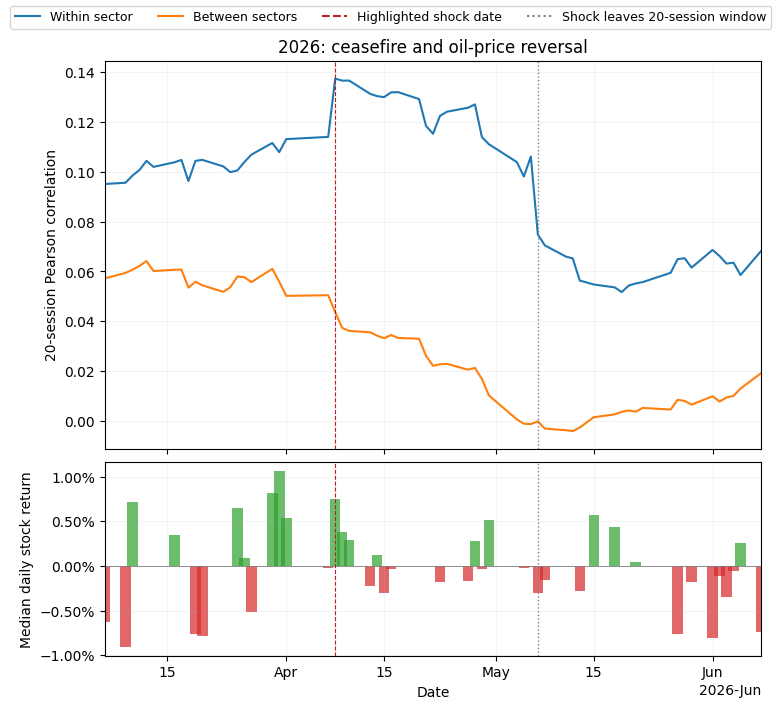

Read down each column: shared daily moves below can raise the rolling correlations above.
Dashed red = highlighted trading day; dotted grey = that day leaves the 20-session window.
The omission table is a sensitivity check on fixed stocks, with fewer dates after omission.
It is not a causal estimate, and valid shock observations are not removed from the main analysis.


In [1]:
from matplotlib import dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# Dates identify historical episodes, not an automatically detected or causal model.
# Sensitivity windows end on the final highlighted date in each episode.
shock_window = 20
shock_events = [
    ("2022: rate fears and Ukraine tensions", "2022-01-24",
     ["2022-01-24"]),
    ("2022: inflation and rate repricing", "2022-06-13",
     ["2022-06-13", "2022-06-16"]),
    ("2022: rate fears and salmon-tax proposal", "2022-09-23",
     ["2022-09-23", "2022-09-28"]),
    ("2023: SVB and Credit Suisse turmoil", "2023-03-13",
     ["2023-03-13", "2023-03-15"]),
    ("2024: global August sell-off", "2024-08-02",
     ["2024-08-02", "2024-08-05"]),
    ("2025: tariff shock", "2025-04-04",
     ["2025-04-03", "2025-04-04", "2025-04-09", "2025-04-10"]),
    ("2026: ceasefire and oil-price reversal", "2026-04-08",
     ["2026-04-08"]),
]
# Median observed-stock return limits the influence of extreme individual returns; not OSEBX.
shock_simple_returns = np.expm1(returns)
shock_daily_median = shock_simple_returns.median(axis=1)
shock_down_fraction = returns.lt(0).sum(axis=1).div(returns.notna().sum(axis=1))


def shock_pair_means(frame: pd.DataFrame) -> tuple[float, float]:
    """Pair-weighted means on the supplied, complete stock sample."""
    corr = frame.corr().to_numpy()
    i, j = np.triu_indices(frame.shape[1], 1)
    sectors = selected.loc[frame.columns, "sector"]
    known = sectors.notna().to_numpy()
    same = sectors.to_numpy()[i] == sectors.to_numpy()[j]
    valid = known[i] & known[j] & np.isfinite(corr[i, j])
    return tuple(corr[i[mask], j[mask]].mean() if mask.any() else np.nan
                 for mask in (valid & same, valid & ~same))


# Apply section 5's full-window support rule at the shorter horizon.
shock_rolling_rows = []
for shock_stop in range(shock_window, len(returns) + 1):
    shock_sample = returns.iloc[shock_stop - shock_window:shock_stop]
    shock_supported = shock_sample.notna().all() & shock_sample.std().gt(0)
    shock_inside, shock_outside = shock_pair_means(shock_sample.loc[:, shock_supported])
    shock_rolling_rows.append({"Date": shock_sample.index[-1],
                               "within": shock_inside, "between": shock_outside})
shock_rolling = pd.DataFrame(shock_rolling_rows).set_index("Date")

shock_rows = []
for shock_title, shock_primary, shock_dates in shock_events:
    shock_dates = pd.DatetimeIndex(shock_dates)
    shock_sample = returns.loc[:shock_dates.max()].iloc[-shock_window:]
    assert len(shock_sample) == shock_window and shock_dates.isin(shock_sample.index).all()
    shock_omitted = shock_sample.drop(index=shock_dates)
    # Hold stocks fixed across both calculations; undefined correlations stay missing.
    shock_supported = (shock_sample.notna().all() & shock_sample.std().gt(0)
                       & shock_omitted.std().gt(0))
    shock_full = shock_pair_means(shock_sample.loc[:, shock_supported])
    shock_without = shock_pair_means(shock_omitted.loc[:, shock_supported])
    shock_rows.append({
        "episode": shock_title, "window_start": shock_sample.index[0].date(),
        "window_end": shock_sample.index[-1].date(),
        "omitted_dates": ", ".join(shock_dates.strftime("%Y-%m-%d")),
        "stocks": int(shock_supported.sum()), "dates_after_omission": len(shock_omitted),
        "within_all": shock_full[0], "within_without_shocks": shock_without[0],
        "between_all": shock_full[1], "between_without_shocks": shock_without[1],
        "primary_day_down_pct": 100 * shock_down_fraction.loc[shock_primary],
    })
shock_summary = pd.DataFrame(shock_rows)
display(shock_summary.round(3))

# Two episodes per figure: correlation above, median daily stock return below.
for shock_offset in range(0, len(shock_events), 2):
    shock_batch = shock_events[shock_offset:shock_offset + 2]
    fig, shock_axes = plt.subplots(2, len(shock_batch), figsize=(7.5 * len(shock_batch), 7),
                                  squeeze=False, sharex="col",
                                  sharey="row", constrained_layout=True,
                                  gridspec_kw={"height_ratios": [2, 1]})
    for shock_col, (shock_title, shock_primary, shock_dates) in enumerate(
        shock_batch
    ):
        shock_dates = pd.DatetimeIndex(shock_dates)
        shock_positions = returns.index.get_indexer(shock_dates)
        # An observation leaves the trailing window after shock_window sessions.
        shock_exits = returns.index[shock_positions + shock_window]
        shock_left = max(0, shock_positions.min() - 20)
        shock_right = min(len(returns), shock_positions.max() + shock_window + 21)
        shock_index = returns.index[shock_left:shock_right]
        shock_view = shock_rolling.reindex(shock_index)
        shock_ax, shock_return_ax = shock_axes[:, shock_col]
        shock_ax.plot(shock_index, shock_view["within"], color="tab:blue", label="Within sector")
        shock_ax.plot(shock_index, shock_view["between"], color="tab:orange", label="Between sectors")
        shock_ax.set(title=shock_title, ylabel=f"{shock_window}-session Pearson correlation")
        shock_values = shock_daily_median.reindex(shock_index)
        shock_return_ax.bar(shock_index, shock_values, width=1.5,
                            color=np.where(shock_values.lt(0), "tab:red", "tab:green"), alpha=0.7)
        shock_return_ax.axhline(0, color="grey", linewidth=0.6)
        shock_return_ax.set(ylabel="Median daily stock return", xlabel="Date")
        shock_return_ax.yaxis.set_major_formatter(PercentFormatter(1))
        for shock_axis in (shock_ax, shock_return_ax):
            for shock_date in shock_dates:
                shock_axis.axvline(shock_date, color="firebrick", linestyle="--", linewidth=0.8)
            for shock_exit in shock_exits:
                shock_axis.axvline(shock_exit, color="grey", linestyle=":", linewidth=1)
            shock_axis.set_xlim(shock_index[0], shock_index[-1])
            shock_axis.grid(alpha=0.15)
        shock_locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
        shock_return_ax.xaxis.set_major_locator(shock_locator)
        shock_return_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(shock_locator))
        shock_handles, _ = shock_ax.get_legend_handles_labels()
        shock_legend_handles = shock_handles + [
            Line2D([], [], color="firebrick", linestyle="--", label="Highlighted shock date"),
            Line2D([], [], color="grey", linestyle=":", label=f"Shock leaves {shock_window}-session window"),
        ]
    fig.legend(handles=shock_legend_handles, loc="outside upper center", ncol=4, fontsize=9)
    plt.show()
    plt.close(fig)

print("Read down each column: shared daily moves below can raise the rolling correlations above.")
print(f"Dashed red = highlighted trading day; dotted grey = that day leaves the {shock_window}-session window.")
print("The omission table is a sensitivity check on fixed stocks, with fewer dates after omission.")
print("It is not a causal estimate, and valid shock observations are not removed from the main analysis.")


## 6. Dependence after removing a dataset market proxy

For each stock, convert other stocks' calculated log returns to simple returns, average
them equally, then use `log1p` of that average as the explanatory return. Excluding the
target stock avoids its direct inclusion in its own proxy. Fit an intercept and slope
by ordinary least squares on the complete-date panel, and compare residual correlations.

This is a contemporaneous descriptive adjustment using a selected-universe proxy,
**not OSEBX, a CAPM test, or an out-of-sample forecast**. Each stock has a slightly
different leave-one-out proxy. Residual sector structure depends on this proxy choice.

,name,alpha,beta,r_squared
stock_id,,,,
NO0010636491,GRONG SPAREBANK,0.000567,-0.115487,0.006077
NO0010808405,ROMERIKE SPAREBK,0.000374,0.045297,0.001262
SE0015193412,AKOBO MINERALS,-0.000985,-0.128199,0.000700
NO0010950249,BERGEN CARBON SOL,-0.001696,0.195353,0.002196
NO0010657505,BORREGAARD,-0.000162,-0.009476,0.000058
...,...,...,...,...
NO0010815673,ELMERA GROUP,0.000312,0.188209,0.007129
NO0010976343,M VEST WATER,-0.000587,0.133786,0.001445
NL0015268814,MPC ENERGY SOLUTIO,-0.000379,0.153575,0.006661


,panel,metric,weighting,within_mean,between_mean,difference,within_pairs,between_pairs,sectors
6,Complete dates,pearson,pairs,0.099286,0.049210,0.050076,2329.0,16586.0,NaN
7,Complete dates,pearson,equal sectors,0.059337,0.043763,0.015574,NaN,NaN,12.0
8,Complete dates,spearman,pairs,0.112901,0.057542,0.055359,2329.0,16586.0,NaN
9,Complete dates,spearman,equal sectors,0.071496,0.051111,0.020385,NaN,NaN,12.0
0,Proxy residuals; complete dates,pearson,pairs,0.080653,0.035176,0.045477,2329.0,16586.0,NaN
1,Proxy residuals; complete dates,pearson,equal sectors,0.049393,0.032404,0.016990,NaN,NaN,12.0
2,Proxy residuals; complete dates,spearman,pairs,0.087520,0.035660,0.051860,2329.0,16586.0,NaN
3,Proxy residuals; complete dates,spearman,equal sectors,0.054113,0.032594,0.021519,NaN,NaN,12.0


,panel,metric,sector,stocks,within_pairs,between_pairs,within_mean,within_median,between_mean,between_median,difference
0,Proxy residuals; complete dates,pearson,Bank,2,1,386,-0.029294,-0.029294,0.012082,0.010802,-0.041376
1,Proxy residuals; complete dates,pearson,Basic Materials,12,66,2196,0.043653,0.022570,0.036396,0.026250,0.007257
2,Proxy residuals; complete dates,pearson,Consumer Discretionary,11,55,2024,0.026894,0.008963,0.032875,0.029975,-0.005982
3,Proxy residuals; complete dates,pearson,Consumer Staples,21,210,3654,0.070997,0.024367,0.026048,0.021547,0.044949
4,Proxy residuals; complete dates,pearson,Energy,35,595,5600,0.125460,0.088307,0.036732,0.031815,0.088729
5,Proxy residuals; complete dates,pearson,Financials,30,435,4950,0.100611,0.068803,0.044077,0.037136,0.056534
6,Proxy residuals; complete dates,pearson,Health Care,13,78,2366,0.015776,0.015907,0.022918,0.021810,-0.007142
7,Proxy residuals; complete dates,pearson,Industrials,38,703,5966,0.057863,0.046280,0.039765,0.034625,0.018098
8,Proxy residuals; complete dates,pearson,Real Estate,4,6,764,0.062138,0.051428,0.039866,0.037114,0.022272
9,Proxy residuals; complete dates,pearson,Technology,18,153,3186,0.043379,0.030081,0.033456,0.029853,0.009923


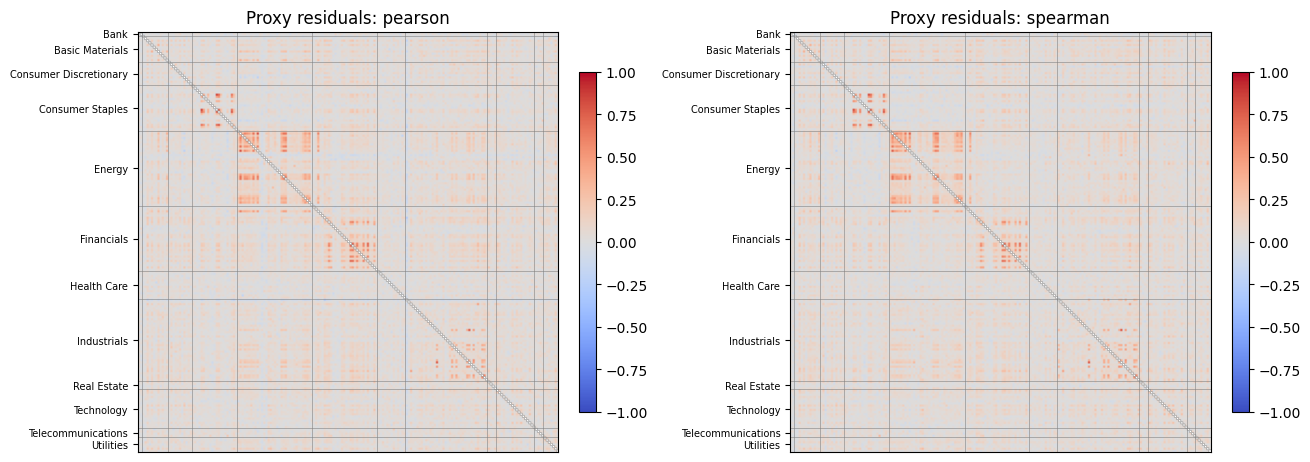

In [9]:
simple = np.expm1(complete)
proxy_simple = (simple.sum(axis=1).to_numpy()[:, None] - simple.to_numpy()) / (len(stock_ids) - 1)
market_proxies = pd.DataFrame(np.log1p(proxy_simple), index=complete.index, columns=stock_ids)
residuals = pd.DataFrame(index=complete.index, columns=stock_ids, dtype=float)
regression_rows = []
for stock_id in stock_ids:
    design = np.column_stack([np.ones(len(complete)), market_proxies[stock_id]])
    coefficients = np.linalg.lstsq(design, complete[stock_id].to_numpy(), rcond=None)[0]
    residuals[stock_id] = complete[stock_id] - design @ coefficients
    regression_rows.append({"stock_id": stock_id, "name": selected.loc[stock_id, "name"],
                            "alpha": coefficients[0], "beta": coefficients[1],
                            "r_squared": 1 - residuals[stock_id].var() / complete[stock_id].var()})
regressions = pd.DataFrame(regression_rows).set_index("stock_id")
residual_matrices, residual_pairs = dependence_pairs(residuals, absolute=False)
residual_global, residual_sectors = sector_summaries(residual_pairs, ["pearson", "spearman"], "Proxy residuals; complete dates")
display(regressions)
display(pd.concat([global_comparison.loc[global_comparison["panel"].eq("Complete dates")
                                         & global_comparison["metric"].isin(["pearson", "spearman"])], residual_global]))
display(residual_sectors)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, metric in zip(axes, ["pearson", "spearman"]):
    matrix = residual_matrices[metric].copy()
    np.fill_diagonal(matrix.values, np.nan)
    im = ax.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1)
    sector_axes(ax)
    ax.set_title("Proxy residuals: " + metric)
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
plt.close(fig)

## 7. Joint lower-tail events

Within each pair-aligned sample, average-rank pseudo-observations are `rank/(n+1)`.
An observation is in the lower tail when its pseudo-observation is at most 0.05.
Ties can change the realised marginal event rates. At least 1,000 paired observations
and 20 events in the conditioning stock are required for a conditional estimate.

The independence reference is the product of the **observed** marginal tail frequencies.
These are finite-threshold co-loss frequencies, not asymptotic tail-dependence estimates.
The smaller complete-date panel may be too short; unavailable values remain blank.

In [10]:
def tail_metrics(x: np.ndarray, y: np.ndarray) -> dict:
    """Estimate rank-tail co-losses with explicit support and conditioning thresholds."""
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    n = len(x)
    out = dict(n_pair=n, tail_n_i=np.nan, tail_n_j=np.nan, joint_count=np.nan,
               joint_probability=np.nan, independence_reference=np.nan,
               conditional_i_given_j=np.nan, conditional_j_given_i=np.nan,
               status="insufficient overlap")
    if n < MIN_TAIL:
        return out
    if np.ptp(x) == 0 or np.ptp(y) == 0:
        out["status"] = "constant series"
        return out
    a = stats.rankdata(x, method="average") / (n + 1) <= TAIL_LEVEL
    b = stats.rankdata(y, method="average") / (n + 1) <= TAIL_LEVEL
    ni, nj, joint = int(a.sum()), int(b.sum()), int((a & b).sum())
    out.update(tail_n_i=ni, tail_n_j=nj, joint_count=joint, joint_probability=joint / n,
               independence_reference=(ni / n) * (nj / n),
               conditional_i_given_j=joint / nj if nj >= MIN_TAIL_EVENTS else np.nan,
               conditional_j_given_i=joint / ni if ni >= MIN_TAIL_EVENTS else np.nan,
               status="available" if min(ni, nj) >= MIN_TAIL_EVENTS else "too few conditioning events")
    return out


tail_parts = []
for label, frame in [("Available pairs", returns), ("Complete dates", complete)]:
    rows = []
    for pair in pair_tables[label].itertuples():
        rows.append({"panel": label, "stock_i": pair.stock_i, "stock_j": pair.stock_j,
                     "name_i": pair.name_i, "name_j": pair.name_j,
                     "known_sectors": pair.known_sectors, "same_sector": pair.same_sector,
                     "sector_i": pair.sector_i, "sector_j": pair.sector_j,
                     "first_date": pair.first_date, "last_date": pair.last_date,
                     **tail_metrics(frame[pair.stock_i].to_numpy(), frame[pair.stock_j].to_numpy())})
    tail_parts.append(pd.DataFrame(rows))
tail_pairs = pd.concat(tail_parts, ignore_index=True)
tail_pairs["joint_excess_over_independence"] = tail_pairs["joint_probability"] - tail_pairs["independence_reference"]
# Symmetric summary; retain both directional conditionals in tail_pairs.
tail_pairs["mean_conditional_coloss"] = tail_pairs[["conditional_i_given_j", "conditional_j_given_i"]].mean(axis=1, skipna=False)
display(tail_pairs.groupby(["panel", "status"]).size().rename("pairs").to_frame())
display(tail_pairs.nlargest(15, "mean_conditional_coloss"))
tail_sector_parts = []
for label, part in tail_pairs.groupby("panel", sort=False):
    g, s = sector_summaries(part, ["joint_probability", "joint_excess_over_independence", "mean_conditional_coloss"], label)
    tail_sector_parts.extend([g.assign(summary="global"), s.assign(summary="sector")])
tail_sector_summary = pd.concat(tail_sector_parts, ignore_index=True)
display(tail_sector_summary)

,,pairs
panel,status,
Available pairs,available,18915
Complete dates,insufficient overlap,18915


,panel,stock_i,stock_j,name_i,name_j,known_sectors,same_sector,sector_i,sector_j,first_date,last_date,n_pair,tail_n_i,tail_n_j,joint_count,joint_probability,independence_reference,conditional_i_given_j,conditional_j_given_i,status,joint_excess_over_independence,mean_conditional_coloss
5226,Available pairs,NO0010073489,NO0003096208,AUSTEVOLL SEAFOOD,LERØY SEAFOOD GP,True,True,Consumer Staples,Consumer Staples,2021-09-08,2026-09-08,1257,62.0,62.0,40.0,0.031822,0.002433,0.645161,0.645161,available,0.029389,0.645161
8042,Available pairs,NO0010345853,NO0003921009,AKER BP,DNO,True,True,Energy,Energy,2021-09-08,2026-09-08,1257,62.0,62.0,36.0,0.028640,0.002433,0.580645,0.580645,available,0.026207,0.580645
8044,Available pairs,NO0010345853,NO0010096985,AKER BP,EQUINOR,True,True,Energy,Energy,2021-09-08,2026-09-08,1257,62.0,62.0,35.0,0.027844,0.002433,0.564516,0.564516,available,0.025411,0.564516
8072,Available pairs,NO0010345853,NO0010234552,AKER BP,AKER,True,False,Energy,Financials,2021-09-08,2026-09-08,1257,62.0,62.0,35.0,0.027844,0.002433,0.564516,0.564516,available,0.025411,0.564516
14361,Available pairs,NO0010631567,NO0006000801,SPAREBANK 1 SØR-NO,SPBK1 NORD-NORGE,True,True,Financials,Financials,2021-09-08,2026-09-08,1257,62.0,62.0,35.0,0.027844,0.002433,0.564516,0.564516,available,0.025411,0.564516
17333,Available pairs,CY0200352116,MHY641771016,FRONTLINE,OKEANIS ECO TANKER,True,True,Industrials,Industrials,2021-09-08,2026-09-08,1257,62.0,62.0,34.0,0.027049,0.002433,0.548387,0.548387,available,0.024616,0.548387
8492,Available pairs,BMG0702P1086,NO0010564701,BW ENERGY LIMITED,PANORO ENERGY,True,True,Energy,Energy,2021-09-08,2026-09-08,1257,62.0,62.0,33.0,0.026253,0.002433,0.532258,0.532258,available,0.023820,0.532258
8635,Available pairs,BMG1738J1247,NO0010564701,BW OFFSHORE LTD,PANORO ENERGY,True,True,Energy,Energy,2021-09-08,2026-09-08,1257,62.0,62.0,33.0,0.026253,0.002433,0.532258,0.532258,available,0.023820,0.532258
13254,Available pairs,NO0010161896,NO0010631567,DNB BANK,SPAREBANK 1 SØR-NO,True,True,Financials,Financials,2021-09-08,2026-09-08,1257,62.0,62.0,32.0,0.025457,0.002433,0.516129,0.516129,available,0.023025,0.516129
14259,Available pairs,NO0006390301,NO0010631567,SPAREBANK 1 SMN,SPAREBANK 1 SØR-NO,True,True,Financials,Financials,2021-09-08,2026-09-08,1257,62.0,62.0,32.0,0.025457,0.002433,0.516129,0.516129,available,0.023025,0.516129


,panel,metric,weighting,within_mean,between_mean,difference,within_pairs,between_pairs,sectors,summary,sector,stocks,within_median,between_median
0,Available pairs,joint_probability,pairs,0.006418,0.004730,0.001689,2329.0,16586.0,NaN,global,NaN,NaN,NaN,NaN
1,Available pairs,joint_probability,equal sectors,0.005044,0.004465,0.000578,NaN,NaN,12.0,global,NaN,NaN,NaN,NaN
2,Available pairs,joint_excess_over_independence,pairs,0.003978,0.002287,0.001691,2329.0,16586.0,NaN,global,NaN,NaN,NaN,NaN
3,Available pairs,joint_excess_over_independence,equal sectors,0.002599,0.002023,0.000577,NaN,NaN,12.0,global,NaN,NaN,NaN,NaN
4,Available pairs,mean_conditional_coloss,pairs,0.129993,0.095756,0.034236,2329.0,16586.0,NaN,global,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,Complete dates,mean_conditional_coloss,NaN,NaN,NaN,NaN,0.0,0.0,NaN,sector,Industrials,38.0,NaN,NaN
80,Complete dates,mean_conditional_coloss,NaN,NaN,NaN,NaN,0.0,0.0,NaN,sector,Real Estate,4.0,NaN,NaN
81,Complete dates,mean_conditional_coloss,NaN,NaN,NaN,NaN,0.0,0.0,NaN,sector,Technology,18.0,NaN,NaN
82,Complete dates,mean_conditional_coloss,NaN,NaN,NaN,NaN,0.0,0.0,NaN,sector,Telecommunications,4.0,NaN,NaN


## 8. Common variation: PCA of standardised returns

Centre and scale each stock by its complete-sample mean and sample standard deviation.
PCA on these data corresponds to the sample correlation matrix, avoiding domination
solely by stocks with larger volatility. Explained-variance shares describe empirical
linear common variation in this selected panel; they do not prove independence of the
remaining components or identify a true number of economic factors.

,PCA
stocks,195.000000
complete_dates,871.000000
first_component_share,0.081733
first_five_share,0.163740
components_for_80pct,108.000000


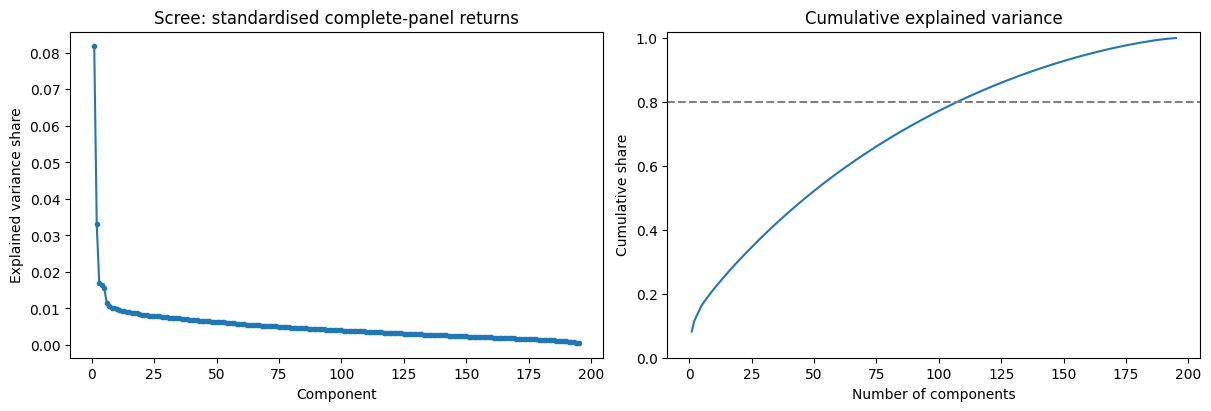

In [11]:
standardised = (complete - complete.mean()) / complete.std(ddof=1)
pca = PCA(svd_solver="full").fit(standardised)
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()
pca_summary = pd.Series({"stocks": len(stock_ids), "complete_dates": len(complete),
    "first_component_share": explained[0], "first_five_share": explained[:5].sum(),
    "components_for_80pct": int(np.searchsorted(cumulative, 0.80) + 1)}, name="PCA").to_frame()
display(pca_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(np.arange(1, len(explained) + 1), explained, marker=".")
axes[0].set(title="Scree: standardised complete-panel returns", xlabel="Component", ylabel="Explained variance share")
axes[1].plot(np.arange(1, len(explained) + 1), cumulative)
axes[1].axhline(0.8, color="grey", linestyle="--")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative share", ylim=(0, 1.02))
plt.show()
plt.close(fig)

## 9. Constrained dynamic time warping

[DTW](https://tslearn.readthedocs.io/en/stable/user_guide/dtw.html) compares paths after
allowing their observations to align at different times. This answers a different
question from simultaneous daily co-movement. It is a distance, not correlation or
direct evidence of diversification.

Partition the original session grid into nonoverlapping 20-return windows. A stock
participates only if all 20 returns are finite and its window variance is positive.
Standardising **within each stock/window** removes level and volatility differences;
the comparison concerns shape. Use a Sakoe–Chiba radius of two sessions and compare
with Euclidean distance on the exact same standardised windows. Both costs are divided
by \(\sqrt{20}\); this is fixed-window scaling, not alignment-path-length normalisation.
At least ten jointly supported windows are required for an aggregate pair distance.

The first two usable windows are benchmarked and their results reused. Numba compilation
can make the first benchmark slower. No windows are sampled or omitted to shorten runtime.

DTW benchmark 1/2: {'window': 0, 'stocks': 189, 'pairs': 17766, 'seconds': 10.64702495886013}


DTW benchmark 2/2: {'window': 1, 'stocks': 187, 'pairs': 17391, 'seconds': 0.17689487501047552}


DTW: 10 complete grid windows processed


DTW: 20 complete grid windows processed


DTW: 30 complete grid windows processed


DTW: 40 complete grid windows processed


... (6 outputs left out)

Pairs below 10 windows: 0


,panel,metric,weighting,within_mean,between_mean,difference,within_pairs,between_pairs,sectors
0,20-session windows,dtw_mean,pairs,0.898606,0.921489,-0.022884,2329.0,16586.0,NaN
1,20-session windows,dtw_mean,equal sectors,0.915105,0.924650,-0.009544,NaN,NaN,12.0
2,20-session windows,euclidean_mean,pairs,1.277464,1.321127,-0.043663,2329.0,16586.0,NaN
3,20-session windows,euclidean_mean,equal sectors,1.309876,1.326521,-0.016644,NaN,NaN,12.0
4,20-session windows,warping_reduction,pairs,0.378859,0.399638,-0.020779,2329.0,16586.0,NaN
5,20-session windows,warping_reduction,equal sectors,0.394771,0.401871,-0.007100,NaN,NaN,12.0


,panel,metric,sector,stocks,within_pairs,between_pairs,within_mean,within_median,between_mean,between_median,difference
0,20-session windows,dtw_mean,Bank,2,1,386,0.912986,0.912986,0.940980,0.942416,-0.027994
1,20-session windows,dtw_mean,Basic Materials,12,66,2196,0.918523,0.925989,0.920181,0.923754,-0.001658
2,20-session windows,dtw_mean,Consumer Discretionary,11,55,2024,0.929051,0.929485,0.926767,0.926131,0.002284
3,20-session windows,dtw_mean,Consumer Staples,21,210,3654,0.904789,0.926653,0.926114,0.926663,-0.021325
4,20-session windows,dtw_mean,Energy,35,595,5600,0.874723,0.892613,0.918615,0.920244,-0.043892
5,20-session windows,dtw_mean,Financials,30,435,4950,0.894244,0.903269,0.915967,0.917634,-0.021724
6,20-session windows,dtw_mean,Health Care,13,78,2366,0.933100,0.933498,0.929603,0.930978,0.003497
7,20-session windows,dtw_mean,Industrials,38,703,5966,0.904405,0.908519,0.915988,0.916862,-0.011583
8,20-session windows,dtw_mean,Real Estate,4,6,764,0.924785,0.935985,0.922219,0.924673,0.002567
9,20-session windows,dtw_mean,Technology,18,153,3186,0.925120,0.924710,0.925800,0.925228,-0.000680


,stock_i,stock_j,name_i,name_j,sector_i,sector_j,known_sectors,same_sector,windows,dtw_mean,euclidean_mean,warping_reduction
5226,NO0010073489,NO0003096208,AUSTEVOLL SEAFOOD,LERØY SEAFOOD GP,Consumer Staples,Consumer Staples,True,True,62,0.479317,0.550224,0.070907
8044,NO0010345853,NO0010096985,AKER BP,EQUINOR,Energy,Energy,True,True,62,0.528454,0.608741,0.080287
6517,NO0003054108,NO0010310956,MOWI,SALMAR,Consumer Staples,Consumer Staples,True,True,62,0.558102,0.634434,0.076332
17333,CY0200352116,MHY641771016,FRONTLINE,OKEANIS ECO TANKER,Industrials,Industrials,True,True,62,0.581426,0.680079,0.098653
14259,NO0006390301,NO0010631567,SPAREBANK 1 SMN,SPAREBANK 1 SØR-NO,Financials,Financials,True,True,62,0.587024,0.692880,0.105856
6354,NO0003096208,NO0003054108,LERØY SEAFOOD GP,MOWI,Consumer Staples,Consumer Staples,True,True,62,0.593230,0.691584,0.098354
8042,NO0010345853,NO0003921009,AKER BP,DNO,Energy,Energy,True,True,62,0.610955,0.721234,0.110279
5227,NO0010073489,NO0003054108,AUSTEVOLL SEAFOOD,MOWI,Consumer Staples,Consumer Staples,True,True,62,0.625326,0.751988,0.126662
14266,NO0006390301,NO0006000801,SPAREBANK 1 SMN,SPBK1 NORD-NORGE,Financials,Financials,True,True,62,0.627777,0.737896,0.110119
6360,NO0003096208,NO0010310956,LERØY SEAFOOD GP,SALMAR,Consumer Staples,Consumer Staples,True,True,62,0.629050,0.734915,0.105866


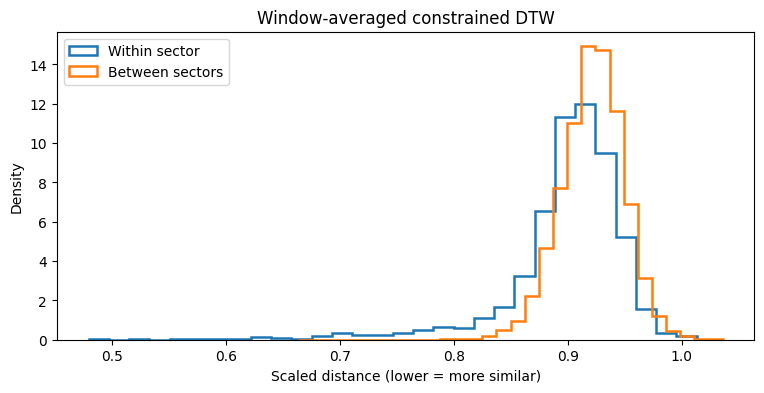

In [12]:
def standardise_window(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Keep only finite, varying stock windows and standardise each independently."""
    finite = np.isfinite(values).all(axis=0)
    indices = np.flatnonzero(finite)
    std = values[:, indices].std(axis=0, ddof=1)
    indices = indices[std > 0]
    sample = values[:, indices].T
    z = (sample - sample.mean(axis=1, keepdims=True)) / sample.std(axis=1, ddof=1, keepdims=True)
    return indices, z


def window_distances(z: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Calculate constrained DTW and unwarped costs on identical window inputs."""
    warped = cdist_dtw(z[:, :, None], global_constraint="sakoe_chiba",
                       sakoe_chiba_radius=DTW_RADIUS, n_jobs=1, be="numpy") / np.sqrt(WINDOW)
    euclidean = squareform(pdist(z, metric="euclidean")) / np.sqrt(WINDOW)
    return warped, euclidean


dtw_sum = np.zeros((len(stock_ids), len(stock_ids)))
euclidean_sum = np.zeros_like(dtw_sum)
window_counts = np.zeros_like(dtw_sum, dtype=int)
window_audit_rows, distance_benchmarks = [], []
dtw_example_windows = {}
dtw_started = perf_counter()
benchmarked = 0
for window_number, offset in enumerate(range(0, len(returns) - WINDOW + 1, WINDOW)):
    part = returns.iloc[offset:offset + WINDOW]
    indices, z = standardise_window(part.to_numpy())
    window_audit_rows.append({"window": window_number, "start": part.index[0], "end": part.index[-1],
                              "supported_stocks": len(indices), "supported_pairs": len(indices) * (len(indices) - 1) // 2})
    if len(indices) < 2:
        continue
    tick = perf_counter()
    warped, euclidean = window_distances(z)
    assert np.all(warped <= euclidean + 1e-9)
    if benchmarked < 2:
        distance_benchmarks.append({"window": window_number, "stocks": len(indices),
                                    "pairs": len(indices) * (len(indices) - 1) // 2,
                                    "seconds": perf_counter() - tick})
        benchmarked += 1
        print(f"DTW benchmark {benchmarked}/2: {distance_benchmarks[-1]}", flush=True)
    ix = np.ix_(indices, indices)
    dtw_sum[ix] += warped
    euclidean_sum[ix] += euclidean
    window_counts[ix] += 1
    # Retain inputs for alignment examples without recomputing the full distance matrices.
    dtw_example_windows[window_number] = (indices, z)
    if (window_number + 1) % 10 == 0:
        print(f"DTW: {window_number + 1} complete grid windows processed", flush=True)
dtw_seconds = perf_counter() - dtw_started
window_audit = pd.DataFrame(window_audit_rows)
dtw_rows = []
for k, (i, j) in enumerate(zip(upper_i, upper_j)):
    n = window_counts[i, j]
    row = pair_tables["Available pairs"].iloc[k][["stock_i", "stock_j", "name_i", "name_j", "sector_i", "sector_j", "known_sectors", "same_sector"]].to_dict()
    row.update(windows=int(n), dtw_mean=dtw_sum[i, j] / n if n >= MIN_DTW_WINDOWS else np.nan,
               euclidean_mean=euclidean_sum[i, j] / n if n >= MIN_DTW_WINDOWS else np.nan)
    dtw_rows.append(row)
dtw_pairs = pd.DataFrame(dtw_rows)
dtw_pairs["warping_reduction"] = dtw_pairs["euclidean_mean"] - dtw_pairs["dtw_mean"]
dtw_global, dtw_sectors = sector_summaries(dtw_pairs, ["dtw_mean", "euclidean_mean", "warping_reduction"], "20-session windows")
print(f"DTW runtime: {dtw_seconds:.1f}s; full grid windows: {len(window_audit)}; "
      f"trailing sessions discarded: {len(returns) % WINDOW}")
display(pd.DataFrame(distance_benchmarks))
display(window_audit)
display(dtw_pairs["windows"].describe().to_frame())
print(f"Pairs below {MIN_DTW_WINDOWS} windows: {dtw_pairs['windows'].lt(MIN_DTW_WINDOWS).sum():,}")
display(dtw_global)
display(dtw_sectors)
display(dtw_pairs.nsmallest(10, "dtw_mean"))
fig, ax = plt.subplots(figsize=(9, 4))
for same, label in [(True, "Within sector"), (False, "Between sectors")]:
    values = dtw_pairs.loc[dtw_pairs["known_sectors"] & dtw_pairs["same_sector"].eq(same), "dtw_mean"].dropna()
    ax.hist(values, bins=30, histtype="step", density=True, linewidth=1.8, label=label)
ax.set(title="Window-averaged constrained DTW", xlabel="Scaled distance (lower = more similar)", ylabel="Density")
ax.legend()
plt.show()
plt.close(fig)

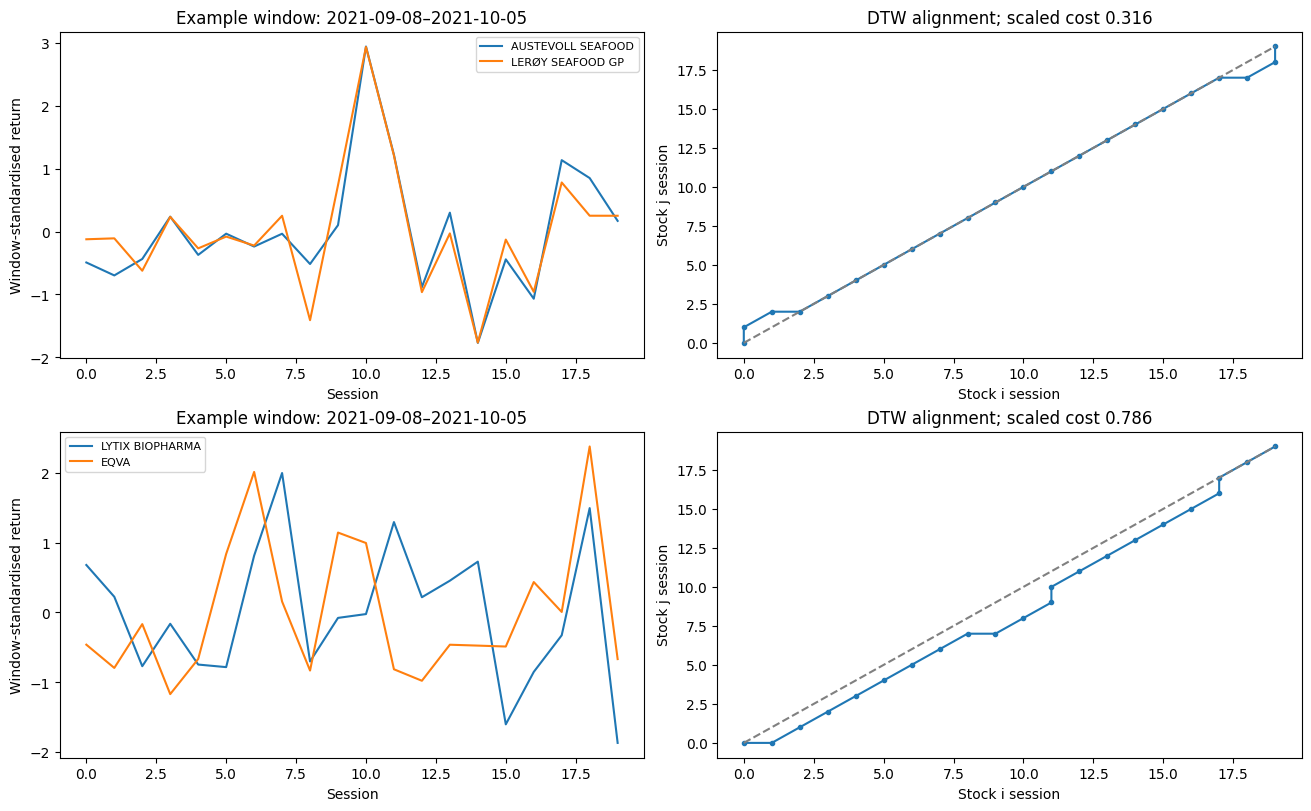

Pairs were chosen by aggregate results; paths show their first jointly supported window.


In [13]:
example_pairs = pd.concat([dtw_pairs.nsmallest(1, "dtw_mean"),
                           dtw_pairs.nlargest(1, "warping_reduction")]).drop_duplicates(["stock_i", "stock_j"])
fig, axes = plt.subplots(len(example_pairs), 2, figsize=(13, 4 * len(example_pairs)), squeeze=False, constrained_layout=True)
alignment_examples = []
for row_number, pair in enumerate(example_pairs.itertuples()):
    i, j = stock_ids.index(pair.stock_i), stock_ids.index(pair.stock_j)
    for number, (indices, z) in dtw_example_windows.items():
        if i in indices and j in indices:
            x, y = z[np.flatnonzero(indices == i)[0]], z[np.flatnonzero(indices == j)[0]]
            path, cost = dtw_path(x, y, global_constraint="sakoe_chiba", sakoe_chiba_radius=DTW_RADIUS, be="numpy")
            axes[row_number, 0].plot(x, label=pair.name_i)
            axes[row_number, 0].plot(y, label=pair.name_j)
            axes[row_number, 0].legend(fontsize=8)
            info = window_audit.loc[window_audit["window"].eq(number)].iloc[0]
            axes[row_number, 0].set(title=f"Example window: {info.start.date()}–{info.end.date()}", xlabel="Session", ylabel="Window-standardised return")
            path_array = np.asarray(path)
            axes[row_number, 1].plot(path_array[:, 0], path_array[:, 1], marker=".")
            axes[row_number, 1].plot([0, WINDOW - 1], [0, WINDOW - 1], linestyle="--", color="grey")
            axes[row_number, 1].set(title=f"DTW alignment; scaled cost {cost / np.sqrt(WINDOW):.3f}", xlabel="Stock i session", ylabel="Stock j session")
            alignment_examples.append({"stock_i": pair.stock_i, "stock_j": pair.stock_j,
                                       "window": number, "cost": cost / np.sqrt(WINDOW)})
            break
plt.show()
plt.close(fig)
print("Pairs were chosen by aggregate results; paths show their first jointly supported window.")

## 10. Validation

These checks verify the actual selection and analytical invariants, and use synthetic
examples for gaps, duplicate conflicts, rank ties, lag orientation, and DTW constraints.
The bootstrap reproducibility check repeats a small prefix of the same seeded algorithm,
not an additional full analysis. No claimed validation below is a model fit or proof
that the vendor's adjusted prices and security identities are economically correct.

In [14]:
# Identity continuity and simultaneous-class separation.
for name, isins in explicit.items():
    assert len({stock_for_isin[i] for i in isins}) == 1, name
for members in {tuple(sorted(m)) for m in history.values()}:
    spans = profiles.loc[list(members)].sort_values("first")
    assert spans["first"].iloc[1:].reset_index(drop=True).gt(spans["last"].iloc[:-1].reset_index(drop=True)).all()
for a, b in [("NO0010571698", "NO0010576010"), ("NO0003399909", "NO0003399917")]:
    assert stock_for_isin[a] != stock_for_isin[b]
assert selected["issuer_key"].is_unique
for key, group in ranked.groupby("issuer_key"):
    assert selected.loc[selected["issuer_key"].eq(key)].index[0] == group.index[0]
assert audit["coverage_eligible"].equals(audit["boundary_ok"] & audit["available_prices"].ge(np.ceil(COVERAGE * len(sessions))))
assert audit["missing_prices"].eq(audit["absent_records"] + audit["recorded_unavailable_prices"]).all()
assert int(audit["selected"].sum()) == len(selected) == funnel.iloc[-1, 0]
assert complete.shape == (int(complete_mask.sum()), len(selected))
assert not complete.isna().any().any()
assert not clean.index.duplicated().any()
assert clean.loc[clean["price_conflict"], "price"].isna().all()
assert all_returns.where(all_prices.loc[sessions].isna() | all_prices.shift().loc[sessions].isna()).isna().all().all()
gap_prices = pd.Series([100., 110., np.nan, 121., 110.])
gap_returns = np.log(gap_prices).diff()
assert pd.isna(gap_returns.iloc[2]) and pd.isna(gap_returns.iloc[3])
assert np.isclose(gap_returns.iloc[1], np.log(1.1))
duplicate_fixture = pd.DataFrame({"date": [0, 0, 1, 1, 2, 2], "price": [100., 100., 110., 120., np.nan, 130.]})
assert duplicate_fixture.groupby("date")["price"].nunique(dropna=False).tolist() == [1, 2, 2]

# Correlations, sample support, sector pair counts, and covariance matrices.
x = np.arange(1000, dtype=float)
fixture = pd.DataFrame({"x": x, "same": x, "opposite": -x, "constant": 1.})
for method in ["pearson", "spearman"]:
    corr = fixture.corr(method=method)
    assert np.isclose(corr.loc["x", "same"], 1) and np.isclose(corr.loc["x", "opposite"], -1)
    assert pd.isna(corr.loc["x", "constant"])
for panel, pairs in pair_tables.items():
    assert len(pairs) == len(stock_ids) * (len(stock_ids) - 1) // 2
    assert not pairs.duplicated(["stock_i", "stock_j"]).any()
    assert pairs["stock_i"].ne(pairs["stock_j"]).all()
    for metric in ["pearson", "spearman", "absolute"]:
        assert pairs[metric].dropna().between(-1 - 1e-10, 1 + 1e-10).all()
        assert pairs.loc[pairs["n_pair"].lt(MIN_PAIR), metric].isna().all()
        observed = sector_comparison.loc[sector_comparison["panel"].eq(panel) & sector_comparison["metric"].eq(metric), "within_pairs"].sum()
        assert observed == pairs.loc[pairs["same_sector"], metric].count()
for covariance in [sample_covariances["Complete dates"], shrinkage_covariance]:
    assert np.allclose(covariance, covariance.T)
    assert np.linalg.eigvalsh(covariance).min() >= -1e-10
assert np.allclose(residuals.mean(), 0, atol=1e-12)
assert np.allclose((residuals * market_proxies).mean(), 0, atol=1e-12)
assert np.isclose(explained.sum(), 1)

# Tail thresholds, ties, and directional conditioning.
t = tail_metrics(x, x)
assert t["joint_count"] == 50 and t["conditional_i_given_j"] == 1
assert np.isclose(t["joint_probability"], 0.05) and np.isclose(t["independence_reference"], 0.0025)
assert np.isnan(tail_metrics(x[:999], x[:999])["joint_probability"])
assert tail_metrics(np.ones(1000), x)["status"] == "constant series"
assert tail_metrics(np.repeat(np.arange(100), 10), np.repeat(np.arange(100), 10))["conditional_i_given_j"] == 1
for metric in ["joint_probability", "independence_reference", "conditional_i_given_j", "conditional_j_given_i"]:
    assert tail_pairs[metric].dropna().between(0, 1).all()
assert tail_pairs.loc[tail_pairs["tail_n_j"].lt(MIN_TAIL_EVENTS), "conditional_i_given_j"].isna().all()
assert tail_pairs.loc[tail_pairs["tail_n_i"].lt(MIN_TAIL_EVENTS), "conditional_j_given_i"].isna().all()

# Positive lag means i precedes j; shifting does not bridge missing grid sessions.
rng = np.random.default_rng(SEED)
leader = pd.Series(rng.normal(size=500))
follower = leader.shift(2)
assert np.isclose(leader.corr(follower.shift(-2)), 1)
assert abs(leader.corr(follower)) < 0.2
assert np.allclose(lag_pairs.loc[lag_pairs["lag"].eq(0), "correlation"], pair_tables["Available pairs"]["pearson"], equal_nan=True)

# Window validity and DTW limiting cases.
z = rng.normal(size=(2, WINDOW))
diagonal_cost = dtw(z[0], z[1], global_constraint="sakoe_chiba", sakoe_chiba_radius=0, be="numpy")
assert np.isclose(diagonal_cost, np.linalg.norm(z[0] - z[1]))
assert dtw(z[0], z[1], global_constraint="sakoe_chiba", sakoe_chiba_radius=2, be="numpy") <= diagonal_cost + 1e-10
window_fixture = np.column_stack([np.arange(WINDOW, dtype=float), np.ones(WINDOW), np.arange(WINDOW, dtype=float)])
window_fixture[5, 2] = np.nan
indices, _ = standardise_window(window_fixture)
assert indices.tolist() == [0]
assert dtw_pairs.loc[dtw_pairs["windows"].lt(MIN_DTW_WINDOWS), "dtw_mean"].isna().all()
assert (dtw_pairs["dtw_mean"].dropna() >= 0).all()
assert (dtw_pairs["warping_reduction"].dropna() >= -1e-9).all()
assert len(window_audit) == len(returns) // WINDOW
repeat = bootstrap_differences(returns, 20, 3, SEED)
np.testing.assert_allclose(repeat, bootstrap_samples[20][:3], equal_nan=True)
assert np.isfinite(bootstrap_samples[20][:, :, 0]).all()
print("All actual-data and synthetic validation checks passed.")

All actual-data and synthetic validation checks passed.


## 11. Computed findings and interpretation limits

Every numerical statement below is drawn from the executed tables. A positive sector
gap indicates higher average internal dependence in this sample; its size, interval,
time variation, and sensitivity to date selection matter more than a binary label.
Lower DTW distances indicate greater similarity, so their sector difference has the
opposite interpretation from a correlation difference.

In [15]:
def global_gap(panel: str, metric: str) -> float:
    """Read the pair-weighted sector gap from the computed comparison table."""
    return float(global_comparison.loc[global_comparison["panel"].eq(panel)
                                       & global_comparison["metric"].eq(metric)
                                       & global_comparison["weighting"].eq("pairs"), "difference"].iloc[0])


primary_ci = bootstrap_ci.loc[bootstrap_ci["block_sessions"].eq(20)
                              & bootstrap_ci["metric"].eq("pearson")
                              & bootstrap_ci["group"].eq("All pairs")].iloc[0]
residual_gap = residual_global.loc[residual_global["metric"].eq("pearson") & residual_global["weighting"].eq("pairs"), "difference"].iloc[0]
tail_available = tail_pairs.loc[tail_pairs["panel"].eq("Available pairs") & tail_pairs["known_sectors"]]
tail_inside = tail_available.loc[tail_available["same_sector"], "mean_conditional_coloss"].mean()
tail_outside = tail_available.loc[~tail_available["same_sector"], "mean_conditional_coloss"].mean()
dtw_gap = dtw_global.loc[dtw_global["metric"].eq("dtw_mean") & dtw_global["weighting"].eq("pairs"), "difference"].iloc[0]
findings = pd.DataFrame([
    {"question": "How many stocks qualify?", "computed_result": f"{len(selected)} selected from {len(audit)} candidate histories; {len(eligible)} pass boundaries/95% before class selection.",
     "limitation": "Endpoint/coverage selection creates survivorship and availability bias; unidentified issuers may still duplicate economic exposure."},
    {"question": "How much data is missing?", "computed_result": f"Selected panel: {int(prices.isna().sum().sum())} missing prices; {int(returns.isna().sum().sum())} missing returns; {len(complete)}/{len(returns)} complete dates.",
     "limitation": "Complete-date results condition on retained sessions; missingness need not be random."},
    {"question": "Are sector peers more correlated?", "computed_result": f"Complete-date Pearson gap {global_gap('Complete dates', 'pearson'):.4f}; 95% block interval [{primary_ci.lower_95:.4f}, {primary_ci.upper_95:.4f}]. Available-pair gap {global_gap('Available pairs', 'pearson'):.4f}.",
     "limitation": "Latest supplied sector labels are fixed retrospectively; compare block sensitivities and pair versus sector weighting."},
    {"question": "Does the result depend on the measure?", "computed_result": f"Complete-date Spearman gap {global_gap('Complete dates', 'spearman'):.4f}; absolute-return correlation gap {global_gap('Complete dates', 'absolute'):.4f}.",
     "limitation": "These measure different forms of association; low correlation is not independence."},
    {"question": "Does common market exposure explain the gap?", "computed_result": f"Residual Pearson gap {residual_gap:.4f}, versus raw {global_gap('Complete dates', 'pearson'):.4f} on the same dates.",
     "limitation": "Leave-one-out equal-weight dataset proxy, not OSEBX or a causal factor model."},
    {"question": "How concentrated is common variation?", "computed_result": f"PC1 {explained[0]:.1%}; first five {explained[:5].sum():.1%}; {int(np.searchsorted(cumulative, .8) + 1)} components for 80%.",
     "limitation": "Empirical linear variation on standardised complete-panel returns, not a proven number of independent factors."},
    {"question": "Do sector peers suffer tail losses together?", "computed_result": f"Available-pair mean conditional co-loss: within {tail_inside:.3f}, between {tail_outside:.3f}; {tail_available.mean_conditional_coloss.notna().sum()} supported pairs.",
     "limitation": "Finite 5% rank threshold and varying paired dates; the complete panel may not meet the 1,000-observation requirement."},
    {"question": "Are warped patterns similar?", "computed_result": f"DTW within-minus-between distance {dtw_gap:.4f}; {dtw_pairs.dtw_mean.notna().sum()} pairs have >= {MIN_DTW_WINDOWS} valid windows; {len(window_audit)} grid windows in {dtw_seconds:.1f}s.",
     "limitation": "Within-window scaling removes volatility; time warping changes alignment. Joint window support varies between pairs."},
    {"question": "What still needs caution?", "computed_result": f"{int(selected.company_id.isna().sum())} selected histories lack issuer ID; {int(selected.sector_changed.sum())} selected histories changed sector label; mean selected zero-return fraction {audit.loc[stock_ids, 'zero_return_fraction'].mean():.1%}.",
     "limitation": "Unresolved identities, stale prices, extreme returns, and vendor adjustment quality remain limitations; flags are not automatic corrections."},
])
with pd.option_context("display.max_colwidth", None):
    display(findings)
print(f"Total notebook runtime: {perf_counter() - started:.1f} seconds")
print("All analyses use calculated adjusted-price returns; no supplied lnDelta fields were loaded.")

,question,computed_result,limitation
0,How many stocks qualify?,195 selected from 292 candidate histories; 197 pass boundaries/95% before class selection.,Endpoint/coverage selection creates survivorship and availability bias; unidentified issuers may still duplicate economic exposure.
1,How much data is missing?,Selected panel: 506 missing prices; 862 missing returns; 871/1257 complete dates.,Complete-date results condition on retained sessions; missingness need not be random.
2,Are sector peers more correlated?,"Complete-date Pearson gap 0.0501; 95% block interval [0.0456, 0.0561]. Available-pair gap 0.0535.",Latest supplied sector labels are fixed retrospectively; compare block sensitivities and pair versus sector weighting.
3,Does the result depend on the measure?,Complete-date Spearman gap 0.0554; absolute-return correlation gap 0.0252.,These measure different forms of association; low correlation is not independence.
4,Does common market exposure explain the gap?,"Residual Pearson gap 0.0455, versus raw 0.0501 on the same dates.","Leave-one-out equal-weight dataset proxy, not OSEBX or a causal factor model."
5,How concentrated is common variation?,PC1 8.2%; first five 16.4%; 108 components for 80%.,"Empirical linear variation on standardised complete-panel returns, not a proven number of independent factors."
6,Do sector peers suffer tail losses together?,"Available-pair mean conditional co-loss: within 0.130, between 0.096; 18915 supported pairs.","Finite 5% rank threshold and varying paired dates; the complete panel may not meet the 1,000-observation requirement."
7,Are warped patterns similar?,DTW within-minus-between distance -0.0229; 18915 pairs have >= 10 valid windows; 62 grid windows in 21.4s.,Within-window scaling removes volatility; time warping changes alignment. Joint window support varies between pairs.
8,What still needs caution?,56 selected histories lack issuer ID; 8 selected histories changed sector label; mean selected zero-return fraction 7.6%.,"Unresolved identities, stale prices, extreme returns, and vendor adjustment quality remain limitations; flags are not automatic corrections."


Total notebook runtime: 191.3 seconds
All analyses use calculated adjusted-price returns; no supplied lnDelta fields were loaded.
